# Medical Dataset Capstone Project
## Heart Attack Risk — Exploratory Analysis & Predictive Modeling

---
# 1. Data Loading & Inspection

This section covers:
- Library imports and configuration
- Loading the medical dataset
- Basic shape, structure, data types, missing values, and summary statistics
- Initial feature engineering needed for later analysis

**Target variable:** `HeartAttackRisk` — indicates whether a heart attack history is recorded in the dataset (0 = no recorded history, 1 = recorded history). This is a predictive classification task based on historical data, not a medical diagnosis or a confirmed estimate of future heart-attack probability.


### Visual Language & Interpretation

- <span style="color:#D62828"><b>Red</b></span>: higher risk, warning signal, or an undesirable value.
- <span style="color:#F4C430"><b>Yellow</b></span>: moderate level or a value that may require attention.
- <span style="color:#2A9D4B"><b>Green</b></span>: more favorable or lower-risk value.
- Text beneath each figure provides an objective interpretation of the displayed pattern.

All prevalence and risk-rate comparisons are descriptive sample-level statistics; they are not medical diagnoses or causal estimates.

---
## Notebook Map

| # | Section | Contents |
|---|---------|----------|
| 1 | Data Loading & Inspection | imports (first cell), loading, quality checks |
| 2 | EDA & Visualizations | EDA figures + engineered-feature visual checks |
| 3 | Preprocessing | leakage-free pipeline, class-weight strategy, artifacts |
| 4 | Supervised Learning | GridSearch + Optuna, Stacking Ensemble (Meta-Learner), leaderboard, test evaluation, clinical thresholds |
| 5 | Unsupervised Learning | clustering, anomaly detection, unsupervised features, association rules, and separately labeled unsupervised visualizations |
| 6 | Neural Network | Keras MLP, Keras MLP, tuning grid, training curves |
| 7 | Supervised Models Comparison | tables, train/val/test charts, ROC and PR curves for all supervised models |\n| 8 | LLM Chat Assistant | OpenAI-powered conversational assistant for project questions |

In [1]:
# ---- Optional packages: installed automatically only if missing (first run in Colab) ----
import sys, importlib, subprocess

def _ensure(pkg, pip_name=None):
    try:
        importlib.import_module(pkg)
    except ImportError:
        print(f"Installing {pip_name or pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=False)

for _pkg in ["xgboost", "lightgbm", "catboost", "optuna", "mlxtend", "openai"]:
    _ensure(_pkg)

# ---- Standard libraries ----
import os, time, warnings
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots

# ---- scikit-learn ----
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest, StackingClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    average_precision_score, roc_auc_score, f1_score, fbeta_score, recall_score,
    precision_score, precision_recall_curve, roc_curve, brier_score_loss,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
)

# ---- Boosted models / tuning / association rules / neural network (optional) ----
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not available - skipping XGBoost")

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
    print("lightgbm not available - skipping LightGBM")

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False
    print("catboost not available - skipping CatBoost")

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
except ImportError:
    HAS_OPTUNA = False
    print("optuna not available - boosted models will use default hyper-parameters")

try:
    from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
    HAS_MLXTEND = True
except ImportError:
    HAS_MLXTEND = False
    print("mlxtend not available - association rules will be skipped")

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("tensorflow not available - neural network section will be skipped")

# ---- Global configuration ----
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pio.templates.default = "plotly_white"
# Consistent semantic palette: red = higher risk/alert, yellow = intermediate, green = favorable
RISK_RED, RISK_YELLOW, RISK_GREEN = "#D62828", "#F4C430", "#2A9D4B"
RISK_SCALE = [[0.0, RISK_GREEN], [0.5, RISK_YELLOW], [1.0, RISK_RED]]
px.defaults.color_discrete_sequence = [RISK_GREEN, RISK_YELLOW, RISK_RED, "#457B9D", "#7A8793"]
px.defaults.color_continuous_scale = RISK_SCALE

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
os.makedirs("figures", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)

Installing catboost ...
Installing optuna ...


In [2]:
# Mount Google Drive only when running inside Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Colab - skipping Google Drive mount.")

Mounted at /content/drive


In [3]:
DATA_FILE = "MedicalDataset.xlsx"
CANDIDATE_PATHS = [
    DATA_FILE,                                   # same folder as the notebook
    os.path.join("data", DATA_FILE),
    os.path.join("/content", DATA_FILE),         # Colab uploaded file
    os.path.join("/content/drive/MyDrive/Colab Notebooks/NTI Final Project", DATA_FILE),  # Drive copy
]
excel_path = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if excel_path is None:
    raise FileNotFoundError(f"{DATA_FILE} not found. Upload it next to the notebook or edit CANDIDATE_PATHS.")
print("Loading:", excel_path)
df = pd.read_excel(excel_path)

# Target rename: HeartAttackRisk (1 = recorded heart-attack history, 0 = no recorded history)
if "HeartAttackRisk" not in df.columns and "HadHeartAttack" in df.columns:
    df = df.rename(columns={"HadHeartAttack": "HeartAttackRisk"})


Loading: /content/drive/MyDrive/Colab Notebooks/NTI Final Project/MedicalDataset.xlsx


In [4]:
df.shape

(10000, 35)

In [5]:
df.head()

,PatientID,State,Sex,AgeCategory,HeightInMeters,WeightInKilograms,BMI,HeartAttackRisk,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos,GeneralHealth
0,1,Alabama,Female,Age 75 to 79,1.68,64,22.7,0,0,0,1,1,0,0,0,1,No,0,0,0,0,0,0,Former smoker,Never used e-cigarettes in my entire life,1,"White only, Non-Hispanic",0,0,1,1,"No, did not receive any tetanus shot in the pa...",0,0,Very good
1,2,Alabama,Female,Age 65 to 69,1.57,61,24.7,0,0,0,0,0,1,1,0,1,No,0,0,0,0,0,0,Former smoker,Never used e-cigarettes in my entire life,1,"White only, Non-Hispanic",0,1,1,1,"No, did not receive any tetanus shot in the pa...",0,0,Very good
2,3,Alabama,Male,Age 60 to 64,1.80,100,30.9,0,0,0,0,0,0,1,0,0,No,0,0,0,0,0,0,Never smoked,Never used e-cigarettes in my entire life,0,"White only, Non-Hispanic",1,0,1,0,"No, did not receive any tetanus shot in the pa...",0,1,Good
3,4,Alabama,Female,Age 70 to 74,1.70,100,34.6,0,0,0,0,0,0,0,0,1,No,0,0,0,0,0,0,Former smoker,Never used e-cigarettes in my entire life,1,"White only, Non-Hispanic",1,0,1,1,"Yes, received tetanus shot, but not Tdap",0,0,Good
4,5,Alabama,Male,Age 50 to 54,1.83,138,41.2,1,1,0,0,0,0,0,1,0,Yes,0,0,0,0,0,0,Former smoker,Never used e-cigarettes in my entire life,1,"White only, Non-Hispanic",1,0,1,1,"No, did not receive any tetanus shot in the pa...",0,1,Excellent


In [6]:
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

1. PatientID
2. State
3. Sex
4. AgeCategory
5. HeightInMeters
6. WeightInKilograms
7. BMI
8. HeartAttackRisk
9. HadAngina
10. HadStroke
11. HadAsthma
12. HadSkinCancer
13. HadCOPD
14. HadDepressiveDisorder
15. HadKidneyDisease
16. HadArthritis
17. HadDiabetes
18. DeafOrHardOfHearing
19. BlindOrVisionDifficulty
20. DifficultyConcentrating
21. DifficultyWalking
22. DifficultyDressingBathing
23. DifficultyErrands
24. SmokerStatus
25. ECigaretteUsage
26. ChestScan
27. RaceEthnicityCategory
28. AlcoholDrinkers
29. HIVTesting
30. FluVaxLast12
31. PneumoVaxEver
32. TetanusLast10Tdap
33. HighRiskLastYear
34. CovidPos
35. GeneralHealth


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  10000 non-null  int64  
 1   State                      10000 non-null  object 
 2   Sex                        10000 non-null  object 
 3   AgeCategory                10000 non-null  object 
 4   HeightInMeters             10000 non-null  float64
 5   WeightInKilograms          10000 non-null  int64  
 6   BMI                        10000 non-null  float64
 7   HeartAttackRisk            10000 non-null  int64  
 8   HadAngina                  10000 non-null  int64  
 9   HadStroke                  10000 non-null  int64  
 10  HadAsthma                  10000 non-null  int64  
 11  HadSkinCancer              10000 non-null  int64  
 12  HadCOPD                    10000 non-null  int64  
 13  HadDepressiveDisorder      10000 non-null  int6

In [8]:
df.dtypes


,0
PatientID,int64
State,object
Sex,object
AgeCategory,object
HeightInMeters,float64
WeightInKilograms,int64
BMI,float64
HeartAttackRisk,int64
HadAngina,int64
HadStroke,int64


In [9]:
df.isnull().sum()

,0
PatientID,0
State,0
Sex,0
AgeCategory,0
HeightInMeters,0
WeightInKilograms,0
BMI,0
HeartAttackRisk,0
HadAngina,0
HadStroke,0


In [10]:
df[['HeightInMeters', 'WeightInKilograms', 'BMI']].describe()

,HeightInMeters,WeightInKilograms,BMI
count,10000.000000,10000.000000,10000.000000
mean,1.705358,83.549800,28.628240
std,0.105944,20.767066,6.235157
min,1.450000,42.000000,15.000000
25%,1.630000,68.000000,24.200000
50%,1.700000,82.000000,27.500000
75%,1.780000,95.000000,32.000000
max,2.050000,180.000000,50.200000


In [11]:
binary_cols = [c for c in df.columns if df[c].dtype == 'int64' and c != 'PatientID']
df[binary_cols].mean().sort_values(ascending=False)

,0
WeightInKilograms,83.5498
AlcoholDrinkers,0.5453
FluVaxLast12,0.5321
ChestScan,0.4270
PneumoVaxEver,0.4068
HadArthritis,0.3465
HIVTesting,0.3428
CovidPos,0.2961
HadDepressiveDisorder,0.2057
DifficultyWalking,0.1489


In [12]:
binary_cols = [c for c in df.columns if df[c].dtype == 'int64' and c != 'PatientID']

print("=== Yes/No Columns Found ===")
print(binary_cols)
print(f"\nTotal binary columns: {len(binary_cols)}")


=== Yes/No Columns Found ===
['WeightInKilograms', 'HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'ChestScan', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'HighRiskLastYear', 'CovidPos']

Total binary columns: 23


In [13]:
# Detailed Yes/No inspection for every binary column
print("="*70)
print("DETAILED YES / NO INSPECTION")
print("="*70)

for col in binary_cols:
    counts = df[col].value_counts().sort_index()
    pct = df[col].value_counts(normalize=True).sort_index() * 100

    print(f"\n▶ {col}")
    print(f"   0 (No)  : {counts.get(0, 0):>8,}  ({pct.get(0, 0):5.2f}%)")
    print(f"   1 (Yes) : {counts.get(1, 0):>8,}  ({pct.get(1, 0):5.2f}%)")

DETAILED YES / NO INSPECTION

▶ WeightInKilograms
   0 (No)  :        0  ( 0.00%)
   1 (Yes) :        0  ( 0.00%)

▶ HeartAttackRisk
   0 (No)  :    9,445  (94.45%)
   1 (Yes) :      555  ( 5.55%)

▶ HadAngina
   0 (No)  :    9,385  (93.85%)
   1 (Yes) :      615  ( 6.15%)

▶ HadStroke
   0 (No)  :    9,582  (95.82%)
   1 (Yes) :      418  ( 4.18%)

▶ HadAsthma
   0 (No)  :    8,515  (85.15%)
   1 (Yes) :    1,485  (14.85%)

▶ HadSkinCancer
   0 (No)  :    9,148  (91.48%)
   1 (Yes) :      852  ( 8.52%)

▶ HadCOPD
   0 (No)  :    9,217  (92.17%)
   1 (Yes) :      783  ( 7.83%)

▶ HadDepressiveDisorder
   0 (No)  :    7,943  (79.43%)
   1 (Yes) :    2,057  (20.57%)

▶ HadKidneyDisease
   0 (No)  :    9,536  (95.36%)
   1 (Yes) :      464  ( 4.64%)

▶ HadArthritis
   0 (No)  :    6,535  (65.35%)
   1 (Yes) :    3,465  (34.65%)

▶ DeafOrHardOfHearing
   0 (No)  :    9,135  (91.35%)
   1 (Yes) :      865  ( 8.65%)

▶ BlindOrVisionDifficulty
   0 (No)  :    9,496  (94.96%)
   1 (Yes) :     

In [14]:
def bmi_category(bmi):
    if bmi < 18.5: return 'Underweight'
    elif bmi < 25: return 'Normal'
    elif bmi < 30: return 'Overweight'
    else: return 'Obese'

df['BMI_Category'] = df['BMI'].apply(bmi_category)

age_order = [
    'Age 18 to 24', 'Age 25 to 29', 'Age 30 to 34', 'Age 35 to 39',
    'Age 40 to 44', 'Age 45 to 49', 'Age 50 to 54', 'Age 55 to 59',
    'Age 60 to 64', 'Age 65 to 69', 'Age 70 to 74', 'Age 75 to 79', 'Age 80 or older'
]
df['AgeCategory'] = pd.Categorical(df['AgeCategory'], categories=age_order, ordered=True)

# NOTE: HadDiabetes = original 4-level column (used as a nominal feature in modeling).
# HasDiabetes = binary flag derived from it (Yes / Yes-during-pregnancy) - used everywhere a 0/1 diabetes rate is needed.
df['HasDiabetes'] = df['HadDiabetes'].isin(['Yes', 'Yes, but only during pregnancy (female)']).astype(int)
df['CurrentSmoker'] = df['SmokerStatus'].str.contains('Current').astype(int)
df['EverSmoker'] = df['SmokerStatus'].isin(['Former smoker', 'Current smoker - now smokes every day', 'Current smoker - now smokes some days']).astype(int)

---
# 2. Exploratory Data Analysis (EDA) & Visualizations

This section examines distributions, relationships, and population-level patterns in the dataset through interactive Plotly visualizations. Each figure is followed by a concise interpretation of the pattern shown, including relevant comparisons and limitations. The commentary describes the data objectively and does not imply causation.

### Figure 1: Prevalence of All Health Conditions & Behaviors (%)


In [15]:
conditions = [
    'HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadSkinCancer',
    'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis',
    'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyWalking',
    'DifficultyConcentrating', 'DifficultyErrands', 'DifficultyDressingBathing',
    'CovidPos', 'AlcoholDrinkers', 'FluVaxLast12', 'PneumoVaxEver', 'HIVTesting'
]

prev = (df[conditions].mean() * 100).sort_values()

fig = px.bar(
    x=prev.values, y=prev.index,
    orientation='h',
    title='Prevalence of All Health Conditions & Behaviors (%)',
    labels={'x': 'Prevalence (%)', 'y': ''},
    text=prev.round(4),
    color=prev.values,
    color_continuous_scale='Teal'
)
fig.update_traces(textposition='outside')
fig.update_layout(height=700, showlegend=False, coloraxis_showscale=False)
fig.show()

Arthritis is among the more frequently reported conditions, while the heart-attack target occurs less often. The difference in prevalence highlights the imbalance between common health conditions and the comparatively uncommon outcome examined in this dataset.

### Figure 2: Age Category Distribution


In [16]:
fig = px.histogram(
    df, x='AgeCategory',
    category_orders={'AgeCategory': age_order},
    title='Age Category Distribution',
    labels={'AgeCategory': 'Age Category', 'count': 'Number of Patients'},
    color_discrete_sequence=['#2a9d8f']
)
fig.update_layout(xaxis_tickangle=-40, bargap=0.15)
fig.show()

The age distribution is concentrated in the older categories. Because the sample is not evenly distributed across age groups, prevalence comparisons are more informative than raw counts when examining age-related patterns.

### Figure 3: Sex Distribution


In [17]:
sex_counts = df['Sex'].value_counts().reset_index()
sex_counts.columns = ['Sex', 'Count']

fig = px.pie(
    sex_counts, names='Sex', values='Count',
    title='Sex Distribution',
    hole=0.4,
    color_discrete_sequence=['#e76f51', '#264653']
)
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.show()

The sample contains more female than male observations. Consequently, charts based on counts may show larger female totals even when the underlying within-group prevalence is similar; rates provide the fairer comparison.

### Figure 4: General Health Status Distribution


In [18]:
gh_order = ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']
gh = df['GeneralHealth'].value_counts().reindex(gh_order).reset_index()
gh.columns = ['GeneralHealth', 'Count']

# Reversing the diverging scale using python slicing
reversed_colors = px.colors.diverging.RdYlGn[::-1]

fig = px.bar(
    gh, x='GeneralHealth', y='Count',
    title='General Health Status Distribution',
    color='GeneralHealth',
    color_discrete_sequence=reversed_colors,
    text='Count'
)
fig.update_traces(textposition='outside')
fig.update_layout(showlegend=False)
fig.show()

The distribution spans the full range of self-reported health categories. The relative concentration in the middle and lower categories provides context for interpreting how perceived health varies across the population.

### Figure 5: BMI Distribution by Category


In [19]:
fig = px.histogram(
    df, x='BMI', nbins=60,
    color='BMI_Category',
    title='BMI Distribution by Category',
    labels={'BMI': 'Body Mass Index', 'count': 'Count'},
    category_orders={'BMI_Category': ['Underweight', 'Normal', 'Overweight', 'Obese']},
    color_discrete_sequence=['#90be6d', '#43aa8b', '#f9c74f', '#f94144']
)
fig.update_layout(bargap=0.05)
fig.show()

The BMI distribution shows variation across the full range, with most observations concentrated in the central values and a smaller number of extreme measurements. These extremes can influence averages and are worth considering when interpreting the distribution.

### Figure 6: BMI Category Distribution (%)


In [20]:
bmi_pct = df['BMI_Category'].value_counts(normalize=True).reindex(
    ['Underweight', 'Normal', 'Overweight', 'Obese']
).mul(100).round(4).reset_index()
bmi_pct.columns = ['BMI_Category', 'Percentage']

fig = px.bar(
    bmi_pct, x='BMI_Category', y='Percentage',
    title='BMI Category Distribution (%)',
    text='Percentage',
    color='BMI_Category',
    color_discrete_sequence=['#90be6d', '#43aa8b', '#f9c74f', '#f94144']
)
fig.update_traces(textposition='outside')
fig.update_layout(showlegend=False)
fig.show()

The category breakdown makes the population composition easier to compare: the normal, overweight, and obese groups represent distinct portions of the sample. The categories simplify interpretation, while the original BMI values retain more detail about individual variation.

### Figure 7: Heart Attack Prevalence by Age and Sex (%)


In [21]:
heart = df.groupby(['AgeCategory', 'Sex'], observed=True)['HeartAttackRisk'].mean().reset_index()
heart['Prevalence'] = heart['HeartAttackRisk'] * 100

fig = px.line(
    heart, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Heart Attack Prevalence by Age and Sex (%)',
    labels={'Prevalence': 'Prevalence (%)', 'AgeCategory': 'Age Category'},
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Heart-attack prevalence varies across age groups and between sexes. The separation between the lines indicates that the association with age is not identical for males and females, while the upward pattern across older age categories highlights age as an important descriptive factor.

### Figure 8: Stroke Prevalence by Age and Sex (%)


In [22]:
stroke = df.groupby(['AgeCategory', 'Sex'], observed=True)['HadStroke'].mean().reset_index()
stroke['Prevalence'] = stroke['HadStroke'] * 100

fig = px.line(
    stroke, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Stroke Prevalence by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Stroke prevalence also changes with age, but the gap between sexes is less pronounced than the pattern observed for heart attack. This comparison shows that different cardiovascular outcomes can have different demographic distributions.

### Figure 9: Diabetes Status by BMI Category (%)


In [23]:
diab = pd.crosstab(df['BMI_Category'], df['HadDiabetes'], normalize='index').mul(100).round(4)
diab = diab.reset_index().melt(id_vars='BMI_Category', var_name='Diabetes Status', value_name='Percentage')

fig = px.bar(
    diab, x='BMI_Category', y='Percentage', color='Diabetes Status',
    barmode='group',
    title='Diabetes Status by BMI Category (%)',
    category_orders={'BMI_Category': ['Underweight', 'Normal', 'Overweight', 'Obese']}
)
fig.show()

The proportion of diabetes cases differs across BMI categories. The chart illustrates a clear relationship between BMI grouping and diabetes prevalence in this sample, although the pattern is observational and does not establish causation.

### Figure 10: Diabetes Prevalence by Age (%)


In [24]:
diab_age = df.groupby('AgeCategory', observed=True)['HasDiabetes'].mean().mul(100).reset_index()
diab_age.columns = ['AgeCategory', 'Prevalence']

fig = px.bar(
    diab_age, x='AgeCategory', y='Prevalence',
    title='Diabetes Prevalence by Age (%)',
    text=diab_age['Prevalence'].round(4),
    color='Prevalence',
    color_continuous_scale='Reds'
)
fig.update_traces(textposition='outside')
fig.update_layout(xaxis_tickangle=-40, coloraxis_showscale=False)
fig.show()

Diabetes prevalence generally rises across older age categories, with the size of the increase varying by age group. Age and BMI should therefore be considered together when describing the distribution of diabetes in this population.

### Figure 11: Smoking Status Distribution


In [25]:
smoke = df['SmokerStatus'].value_counts().reset_index()
smoke.columns = ['SmokerStatus', 'Count']

fig = px.bar(
    smoke, x='SmokerStatus', y='Count',
    title='Smoking Status Distribution',
    text='Count',
    color='SmokerStatus'
)
fig.update_traces(textposition='outside')
fig.update_layout(xaxis_tickangle=-25, showlegend=False)
fig.show()

Smoking status is distributed across several distinct categories rather than a simple smoker/non-smoker split. The chart makes the relative size of never, former, and current smoking groups visible and preserves meaningful differences in smoking history.

### Figure 12: Heart Conditions & COPD by Smoking Status (%)


In [26]:
smoke_heart = df.groupby('SmokerStatus')[['HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadCOPD']].mean().mul(100)
smoke_heart = smoke_heart.reset_index().melt(id_vars='SmokerStatus', var_name='Condition', value_name='Prevalence')

fig = px.bar(
    smoke_heart, x='SmokerStatus', y='Prevalence', color='Condition',
    barmode='group',
    title='Heart Conditions & COPD by Smoking Status (%)'
)
fig.update_layout(xaxis_tickangle=-20)
fig.show()

The prevalence of heart-related conditions and COPD differs across smoking-status groups. The pattern is consistent with a broader association between smoking history and respiratory or cardiovascular burden, while the chart alone cannot establish a causal effect.

### Figure 13: Depressive Disorder Prevalence by Age and Sex (%)


In [27]:
dep = df.groupby(['AgeCategory', 'Sex'], observed=True)['HadDepressiveDisorder'].mean().mul(100).reset_index()
dep.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    dep, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Depressive Disorder Prevalence by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Depressive-disorder prevalence differs across age and sex groups. The separation between the plotted groups indicates that the distribution is not uniform across the population and should be interpreted in the context of the sample composition.

### Figure 14: Difficulty Walking by Age and Arthritis Status (%)


In [28]:
arth = df.groupby(['AgeCategory', 'HadArthritis'], observed=True)['DifficultyWalking'].mean().mul(100).reset_index()
arth['HadArthritis'] = arth['HadArthritis'].map({0: 'No Arthritis', 1: 'Has Arthritis'})

fig = px.line(
    arth, x='AgeCategory', y='DifficultyWalking', color='HadArthritis',
    markers=True,
    title='Difficulty Walking by Age and Arthritis Status (%)',
    labels={'DifficultyWalking': 'Prevalence of Difficulty Walking (%)'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Difficulty walking is more common in older age categories, and the chart compares this pattern between people with and without arthritis. The difference between these groups illustrates the close descriptive relationship between joint conditions and mobility limitations.

### Figure 15: Correlation Heatmap of Key Health Indicators


In [29]:
corr_cols = [
    'HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadCOPD', 'HadAsthma',
    'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HasDiabetes',
    'DifficultyWalking', 'BMI', 'AlcoholDrinkers', 'CurrentSmoker', 'CovidPos'
]

corr = df[corr_cols].corr().round(4)

fig = px.imshow(
    corr,
    text_auto='.4f',
    aspect='auto',
    color_continuous_scale='RdBu_r',
    zmin=-0.5, zmax=0.5,
    title='Correlation Heatmap of Key Health Indicators'
)
fig.update_layout(height=750, width=850)
fig.show()

Several health indicators show positive relationships with one another, indicating that chronic conditions often occur together rather than independently. Correlation describes co-occurrence and should not be interpreted as evidence that one condition causes another.

### Figure 16: General Health Composition by Age (%)


In [30]:
gh_age = pd.crosstab(df['AgeCategory'], df['GeneralHealth'], normalize='index').mul(100)
gh_age = gh_age.reindex(columns=['Excellent', 'Very good', 'Good', 'Fair', 'Poor'])
gh_age = gh_age.reset_index().melt(id_vars='AgeCategory', var_name='GeneralHealth', value_name='Percentage')

# Reversing the diverging scale RdYlGn to make Excellent green and Poor red
reversed_colors = px.colors.diverging.RdYlGn[::-1]

fig = px.area(
    gh_age, x='AgeCategory', y='Percentage', color='GeneralHealth',
    title='General Health Composition by Age (%)',
    category_orders={'GeneralHealth': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']},
    color_discrete_sequence=reversed_colors
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

The proportion of respondents reporting fair or poor health increases across older age categories, while excellent or very good health becomes less common. This pattern shows a clear age gradient in self-rated health.

### Figure 17: Key Conditions Prevalence by Race/Ethnicity (%)


In [31]:
race = df.groupby('RaceEthnicityCategory')[
    ['HeartAttackRisk', 'HasDiabetes', 'HadDepressiveDisorder', 'CovidPos', 'HadCOPD']
].mean().mul(100).round(4)

race = race.reset_index().melt(id_vars='RaceEthnicityCategory', var_name='Condition', value_name='Prevalence')

fig = px.bar(
    race, x='RaceEthnicityCategory', y='Prevalence', color='Condition',
    barmode='group',
    title='Key Conditions Prevalence by Race/Ethnicity (%)'
)
fig.update_layout(xaxis_tickangle=-25)
fig.show()

The prevalence of selected conditions varies across race and ethnicity categories. These are unadjusted group comparisons; differences may reflect age composition, socioeconomic context, access to care, and other factors not represented in the chart.

### Figure 18: BMI Distribution by General Health and Sex


In [32]:
fig = px.box(
    df, x='GeneralHealth', y='BMI', color='Sex',
    title='BMI Distribution by General Health and Sex',
    category_orders={'GeneralHealth': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']},
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.show()

BMI distributions differ across self-rated health categories, with shifts in the median and spread visible between groups. The box plots also reveal variation and extreme observations within each category, rather than only differences in average BMI.

### Figure 19: Preventive Care & Testing Rates (%)


In [33]:
vax = df[['FluVaxLast12', 'PneumoVaxEver', 'HIVTesting', 'ChestScan']].mean().mul(100).round(4)
vax = vax.reset_index()
vax.columns = ['Type', 'Rate']

fig = px.bar(
    vax, x='Type', y='Rate',
    title='Preventive Care & Testing Rates (%)',
    text='Rate',
    color='Rate',
    color_continuous_scale='Blues'
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False)
fig.show()

The chart compares uptake of preventive services and testing. These measures represent different types of healthcare engagement, and a diagnostic scan may be more closely related to existing clinical concerns than to routine prevention.

### Figure 20: COPD Prevalence by Smoking Status × E-Cigarette Use (%)


In [34]:
df['SmokingGroup'] = 'Never'
df.loc[df['SmokerStatus'].str.contains('Former'), 'SmokingGroup'] = 'Former'
df.loc[df['SmokerStatus'].str.contains('Current'), 'SmokingGroup'] = 'Current'

df['ECigGroup'] = df['ECigaretteUsage'].apply(
    lambda x: 'Current E-Cig' if 'every day' in x or 'some days' in x
    else ('Former E-Cig' if 'Not at all' in x else 'Never E-Cig')
)

ecig = df.groupby(['SmokingGroup', 'ECigGroup'])['HadCOPD'].mean().mul(100).reset_index()
ecig.columns = ['SmokingGroup', 'ECigGroup', 'Prevalence']

fig = px.bar(
    ecig, x='SmokingGroup', y='Prevalence', color='ECigGroup',
    barmode='group',
    title='COPD Prevalence by Smoking Status × E-Cigarette Use (%)'
)
fig.show()

COPD prevalence varies across smoking groups, while e-cigarette use adds another layer of subgroup variation. Because conventional smoking history and e-cigarette use may overlap, the plotted differences should not be interpreted as isolated effects.

### Figure 21: Number of Chronic Conditions per Person


In [35]:
chronic = ['HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadCOPD',
           'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HasDiabetes']

df['ChronicCount'] = df[chronic].sum(axis=1)

fig = px.histogram(
    df, x='ChronicCount',
    title='Number of Chronic Conditions per Person',
    labels={'ChronicCount': 'Number of Chronic Conditions', 'count': 'Number of People'},
    color_discrete_sequence=['#9b5de5'],
    nbins=10
)
fig.update_layout(bargap=0.15)
fig.show()

The distribution summarizes the number of chronic conditions recorded for each person. Since this count includes the heart-attack target, it is used only for descriptive analysis and is excluded from model inputs to prevent target leakage.

### Figure 22: Average Number of Chronic Conditions by Age


In [36]:
chronic_age = df.groupby('AgeCategory', observed=True)['ChronicCount'].mean().reset_index()

fig = px.bar(
    chronic_age, x='AgeCategory', y='ChronicCount',
    title='Average Number of Chronic Conditions by Age',
    text=chronic_age['ChronicCount'].round(4),
    color='ChronicCount',
    color_continuous_scale='Purples'
)
fig.update_traces(textposition='outside')
fig.update_layout(xaxis_tickangle=-40, coloraxis_showscale=False)
fig.show()

The average number of chronic conditions increases across older age categories. This indicates a higher recorded burden of coexisting conditions among older respondents in the sample.

### Figure 23: Heart Attack Prevalence by BMI Category and Sex (%)


In [37]:
heart_bmi = df.groupby(['BMI_Category', 'Sex'])['HeartAttackRisk'].mean().mul(100).reset_index()
heart_bmi.columns = ['BMI_Category', 'Sex', 'Prevalence']

fig = px.bar(
    heart_bmi, x='BMI_Category', y='Prevalence', color='Sex',
    barmode='group',
    title='Heart Attack Prevalence by BMI Category and Sex (%)',
    category_orders={'BMI_Category': ['Underweight', 'Normal', 'Overweight', 'Obese']},
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'},
    text=heart_bmi['Prevalence'].round(4)
)
fig.update_traces(textposition='outside')
fig.show()

Heart-attack prevalence differs between sexes across BMI categories. The variation across BMI groups is not identical for males and females, showing why the relationship is better understood through the combined categories than through BMI alone.

### Figure 24: Stroke Prevalence by BMI Category and Sex (%)


In [38]:
stroke_bmi = df.groupby(['BMI_Category', 'Sex'])['HadStroke'].mean().mul(100).reset_index()
stroke_bmi.columns = ['BMI_Category', 'Sex', 'Prevalence']

fig = px.bar(
    stroke_bmi, x='BMI_Category', y='Prevalence', color='Sex',
    barmode='group',
    title='Stroke Prevalence by BMI Category and Sex (%)',
    category_orders={'BMI_Category': ['Underweight', 'Normal', 'Overweight', 'Obese']},
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'},
    text=stroke_bmi['Prevalence'].round(4)
)
fig.update_traces(textposition='outside')
fig.show()

Stroke prevalence changes only modestly across some BMI categories compared with the differences observed across age groups elsewhere in the analysis. BMI category alone therefore provides a limited description of stroke variation in this sample.

### Figure 25: Diabetes Prevalence by Age and Sex (%)


In [39]:
diab_sex = df.groupby(['AgeCategory', 'Sex'], observed=True)['HasDiabetes'].mean().mul(100).reset_index()
diab_sex.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    diab_sex, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Diabetes Prevalence by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Diabetes prevalence rises across age categories for both sexes. The distance between the lines indicates the size of the sex difference within each age group, while the overall upward pattern is primarily associated with age.

### Figure 26: COPD Prevalence by Age and Smoking Status (%)


In [40]:
copd = df.groupby(['AgeCategory', 'SmokingGroup'], observed=True)['HadCOPD'].mean().mul(100).reset_index()
copd.columns = ['AgeCategory', 'SmokingGroup', 'Prevalence']

fig = px.line(
    copd, x='AgeCategory', y='Prevalence', color='SmokingGroup',
    markers=True,
    title='COPD Prevalence by Age and Smoking Status (%)'
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

COPD prevalence is higher in some older age and smoking-status groups than in others. The combined view highlights how age and smoking history coincide with differences in respiratory disease prevalence.

### Figure 27: Depressive Disorder Prevalence by BMI Category (%)


In [41]:
dep_bmi = df.groupby('BMI_Category')['HadDepressiveDisorder'].mean().mul(100).reindex(
    ['Underweight', 'Normal', 'Overweight', 'Obese']
).reset_index()
dep_bmi.columns = ['BMI_Category', 'Prevalence']

fig = px.bar(
    dep_bmi, x='BMI_Category', y='Prevalence',
    title='Depressive Disorder Prevalence by BMI Category (%)',
    text=dep_bmi['Prevalence'].round(4),
    color='Prevalence',
    color_continuous_scale='Purples'
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False)
fig.show()

Depressive-disorder prevalence varies across BMI categories, but the differences are comparatively modest. BMI category alone does not capture the full variation in mental-health status represented in the dataset.

### Figure 28: Difficulty Walking Prevalence by Age and Sex (%)


In [42]:
walk = df.groupby(['AgeCategory', 'Sex'], observed=True)['DifficultyWalking'].mean().mul(100).reset_index()
walk.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    walk, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Difficulty Walking Prevalence by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Difficulty walking becomes more prevalent in older age groups, with differences also visible between sexes. The chart illustrates the concentration of mobility limitations among older respondents.

### Figure 29: Kidney Disease Prevalence by Age and Diabetes Status (%)


In [43]:
kidney = df.groupby(['AgeCategory', 'HasDiabetes'], observed=True)['HadKidneyDisease'].mean().mul(100).reset_index()
kidney['HasDiabetes'] = kidney['HasDiabetes'].map({0: 'No Diabetes', 1: 'Has Diabetes'})
kidney.columns = ['AgeCategory', 'Diabetes', 'Prevalence']

fig = px.line(
    kidney, x='AgeCategory', y='Prevalence', color='Diabetes',
    markers=True,
    title='Kidney Disease Prevalence by Age and Diabetes Status (%)'
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Kidney-disease prevalence is higher among respondents with diabetes across age categories. The pattern suggests that diabetes and kidney disease frequently co-occur in this sample, although the comparison is descriptive rather than causal.

### Figure 30: Arthritis Prevalence by Age and Sex (%)


In [44]:
arth_sex = df.groupby(['AgeCategory', 'Sex'], observed=True)['HadArthritis'].mean().mul(100).reset_index()
arth_sex.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    arth_sex, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Arthritis Prevalence by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Arthritis prevalence increases across age categories, with the chart also showing differences between sexes. This age-related pattern is consistent with the mobility limitations displayed in the earlier analysis.

### Figure 31: Prevalence of Functional Disabilities (%)


In [45]:
disabilities = ['DeafOrHardOfHearing', 'BlindOrVisionDifficulty',
                'DifficultyConcentrating', 'DifficultyWalking',
                'DifficultyDressingBathing', 'DifficultyErrands']

dis_prev = (df[disabilities].mean() * 100).sort_values(ascending=True)

fig = px.bar(
    x=dis_prev.values, y=dis_prev.index,
    orientation='h',
    title='Prevalence of Functional Disabilities (%)',
    text=dis_prev.round(4),
    color=dis_prev.values,
    color_continuous_scale='Oranges'
)
fig.update_traces(textposition='outside')
fig.update_layout(height=500, coloraxis_showscale=False)
fig.show()

The prevalence bars show that functional difficulties are not equally common across domains. Differences between hearing, vision, concentration, mobility, and daily-activity measures provide a broader picture of functional health.

### Figure 32: Average Number of Functional Disabilities by Age


In [46]:
df['DisabilityCount'] = df[disabilities].sum(axis=1)

dis_age = df.groupby('AgeCategory', observed=True)['DisabilityCount'].mean().reset_index()

fig = px.bar(
    dis_age, x='AgeCategory', y='DisabilityCount',
    title='Average Number of Functional Disabilities by Age',
    text=dis_age['DisabilityCount'].round(4),
    color='DisabilityCount',
    color_continuous_scale='Oranges'
)
fig.update_traces(textposition='outside')
fig.update_layout(xaxis_tickangle=-40, coloraxis_showscale=False)
fig.show()

The average number of functional limitations increases with age. This indicates that multiple aspects of daily functioning are affected more frequently in older age groups.

### Figure 33: COVID-19 Positive Rate by Age and Sex (%)


In [47]:
covid = df.groupby(['AgeCategory', 'Sex'], observed=True)['CovidPos'].mean().mul(100).reset_index()
covid.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    covid, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='COVID-19 Positive Rate by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

The COVID-19 positive rate varies across age and sex groups. The differences are descriptive and may reflect exposure, testing, reporting, and sample composition as well as underlying infection patterns.

### Figure 34: Alcohol Drinkers Prevalence by Age and Sex (%)


In [48]:
alcohol = df.groupby(['AgeCategory', 'Sex'], observed=True)['AlcoholDrinkers'].mean().mul(100).reset_index()
alcohol.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    alcohol, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Alcohol Drinkers Prevalence by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

Alcohol-drinker prevalence differs across age and sex groups. The chart describes variation in reported behavior and should not be read as evidence of a direct effect on heart-attack occurrence.

### Figure 35: High Risk Behavior (Last Year) by Age and Sex (%)


In [49]:
highrisk = df.groupby(['AgeCategory', 'Sex'], observed=True)['HighRiskLastYear'].mean().mul(100).reset_index()
highrisk.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    highrisk, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='High Risk Behavior (Last Year) by Age and Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

The prevalence of high-risk behavior in the previous year varies across demographic groups. The age and sex breakdown makes these differences visible without implying that the behavior alone explains later health outcomes.

### Figure 36: Comorbidity Matrix: Probability of Condition B given Condition A (%)


In [50]:
comorbid_cols = ['HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadCOPD',
                 'HadAsthma', 'HadDepressiveDisorder', 'HadKidneyDisease',
                 'HadArthritis', 'HasDiabetes', 'DifficultyWalking']

# Calculate conditional probability matrix
comorbid_matrix = pd.DataFrame(index=comorbid_cols, columns=comorbid_cols)

for col1 in comorbid_cols:
    for col2 in comorbid_cols:
        if col1 == col2:
            comorbid_matrix.loc[col1, col2] = 100
        else:
            # P(col2 | col1)
            comorbid_matrix.loc[col1, col2] = (df[df[col1]==1][col2].mean() * 100).round(4)

comorbid_matrix = comorbid_matrix.astype(float)

fig = px.imshow(
    comorbid_matrix,
    text_auto='.4f',
    aspect='auto',
    color_continuous_scale='YlOrRd',
    title='Comorbidity Matrix: Probability of Condition B given Condition A (%)'
)
fig.update_layout(height=700, width=800)
fig.show()

The conditional-probability matrix shows how often one condition is observed among respondents who report another. Higher values identify stronger co-occurrence within the sample, not causal relationships between conditions.

### Figure 37: Top 10 States by Heart Attack Prevalence (%)


In [51]:
state_heart = df.groupby('State')['HeartAttackRisk'].mean().mul(100).sort_values(ascending=False).head(10).reset_index()
state_heart.columns = ['State', 'Prevalence']

fig = px.bar(
    state_heart, x='Prevalence', y='State',
    orientation='h',
    title='Top 10 States by Heart Attack Prevalence (%)',
    text=state_heart['Prevalence'].round(4),
    color='Prevalence',
    color_continuous_scale='Reds'
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False, yaxis={'categoryorder':'total ascending'})
fig.show()

Heart-attack prevalence differs across the states shown in the chart. These state-level rates describe geographic variation in the sample and may be influenced by demographic composition or other regional factors.

### Figure 38: Top 10 States by Diabetes Prevalence (%)


In [52]:
state_diab = df.groupby('State')['HasDiabetes'].mean().mul(100).sort_values(ascending=False).head(10).reset_index()
state_diab.columns = ['State', 'Prevalence']

fig = px.bar(
    state_diab, x='Prevalence', y='State',
    orientation='h',
    title='Top 10 States by Diabetes Prevalence (%)',
    text=state_diab['Prevalence'].round(4),
    color='Prevalence',
    color_continuous_scale='Oranges'
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False, yaxis={'categoryorder':'total ascending'})
fig.show()

Diabetes prevalence also varies across states. Comparing the geographic patterns across health outcomes helps distinguish conditions with similar regional distributions from those with different patterns.

### Figure 39: Top 10 States by Depressive Disorder Prevalence (%)


In [53]:
state_dep = df.groupby('State')['HadDepressiveDisorder'].mean().mul(100).sort_values(ascending=False).head(10).reset_index()
state_dep.columns = ['State', 'Prevalence']

fig = px.bar(
    state_dep, x='Prevalence', y='State',
    orientation='h',
    title='Top 10 States by Depressive Disorder Prevalence (%)',
    text=state_dep['Prevalence'].round(4),
    color='Prevalence',
    color_continuous_scale='Purples'
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False, yaxis={'categoryorder':'total ascending'})
fig.show()

Depressive-disorder prevalence shows its own geographic distribution, which does not necessarily match the state-level patterns for heart attack or diabetes. This emphasizes that health outcomes can vary independently across regions.

### Figure 40: Top 15 States by Current Smoking Rate (%)


In [54]:
state_smoke = df.groupby('State')['CurrentSmoker'].mean().mul(100).sort_values(ascending=False).head(15).reset_index()
state_smoke.columns = ['State', 'Prevalence']

fig = px.bar(
    state_smoke, x='Prevalence', y='State',
    orientation='h',
    title='Top 15 States by Current Smoking Rate (%)',
    text=state_smoke['Prevalence'].round(4),
    color='Prevalence',
    color_continuous_scale='Greys'
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False, yaxis={'categoryorder':'total ascending'})
fig.show()

Current-smoking prevalence differs across states, indicating geographic variation in the reported behavior. These state-level differences provide context for interpreting the regional patterns in respiratory and cardiovascular conditions.

### Figure 41: Top 20 Highest Heart Attack Risk Combinations (Age + Sex + Smoking + BMI)


In [55]:
# Create risk groups
df['RiskGroup'] = (
    df['AgeCategory'].astype(str) + ' | ' +
    df['Sex'] + ' | ' +
    df['SmokingGroup'] + ' | ' +
    df['BMI_Category']
)

# Focus on highest risk combinations
risk = df.groupby(['AgeCategory', 'Sex', 'SmokingGroup', 'BMI_Category'], observed=True)['HeartAttackRisk'].agg(['mean', 'count']).reset_index()
risk = risk[risk['count'] >= 50]  # only reliable groups
risk['Prevalence'] = (risk['mean'] * 100).round(4)
risk = risk.sort_values('Prevalence', ascending=False).head(20)

risk['Label'] = (
    risk['AgeCategory'].astype(str) + ' | ' +
    risk['Sex'] + ' | ' +
    risk['SmokingGroup'] + ' | ' +
    risk['BMI_Category']
)

fig = px.bar(
    risk, x='Prevalence', y='Label',
    orientation='h',
    title='Top 20 Highest Heart Attack Risk Combinations (Age + Sex + Smoking + BMI)',
    text='Prevalence',
    color='Prevalence',
    color_continuous_scale='Reds'
)
fig.update_traces(textposition='outside')
fig.update_layout(height=700, coloraxis_showscale=False, yaxis={'categoryorder':'total ascending'})
fig.show()

The highest observed heart-attack rates occur in selected combinations of age, sex, smoking status, and BMI. The chart highlights the importance of considering overlapping characteristics rather than interpreting each factor in isolation.

### Figure 42: Relative Risk of Heart Attack (Baseline = Never Smoker + Normal BMI = 1.0)


In [56]:
# Baseline: Never smoker + Normal BMI
baseline = df[(df['SmokingGroup'] == 'Never') & (df['BMI_Category'] == 'Normal')]['HeartAttackRisk'].mean()

risk_rel = df.groupby(['SmokingGroup', 'BMI_Category'])['HeartAttackRisk'].mean().reset_index()
risk_rel['RelativeRisk'] = (risk_rel['HeartAttackRisk'] / baseline).round(4)
risk_rel['Prevalence'] = (risk_rel['HeartAttackRisk'] * 100).round(4)

fig = px.bar(
    risk_rel, x='BMI_Category', y='RelativeRisk', color='SmokingGroup',
    barmode='group',
    title=f'Relative Risk of Heart Attack (Baseline = Never Smoker + Normal BMI = 1.0)',
    category_orders={'BMI_Category': ['Underweight', 'Normal', 'Overweight', 'Obese']},
    text='RelativeRisk'
)
fig.update_traces(textposition='outside')
fig.add_hline(y=1, line_dash='dash', line_color='gray', annotation_text='Baseline')
fig.show()

Relative-risk values compare each smoking and BMI group with the selected reference group. Values above 1 indicate a higher observed rate than the reference, while values below 1 indicate a lower observed rate; the comparison remains observational.

### Figure 43: Diabetes Prevalence Heatmap by Age and BMI Category (%)


In [57]:
diab_risk = df.groupby(['AgeCategory', 'BMI_Category'], observed=True)['HasDiabetes'].mean().mul(100).reset_index()
diab_risk.columns = ['AgeCategory', 'BMI_Category', 'Prevalence']

fig = px.density_heatmap(
    diab_risk, x='AgeCategory', y='BMI_Category', z='Prevalence',
    title='Diabetes Prevalence Heatmap by Age and BMI Category (%)',
    category_orders={
        'AgeCategory': age_order,
        'BMI_Category': ['Underweight', 'Normal', 'Overweight', 'Obese']
    },
    color_continuous_scale='YlOrRd',
    text_auto='.4f'
)
fig.update_layout(xaxis_tickangle=-40, height=500)
fig.show()

The heatmap shows how diabetes prevalence changes across the joint categories of age and BMI. The strongest values occur where the two characteristics coincide, illustrating the additional detail gained from examining their combination.

### Figure 44: Probability of Having 3 or More Chronic Conditions by Age & Sex (%)


In [58]:
df['Has3PlusChronic'] = (df['ChronicCount'] >= 3).astype(int)

multi = df.groupby(['AgeCategory', 'Sex'], observed=True)['Has3PlusChronic'].mean().mul(100).reset_index()
multi.columns = ['AgeCategory', 'Sex', 'Prevalence']

fig = px.line(
    multi, x='AgeCategory', y='Prevalence', color='Sex',
    markers=True,
    title='Probability of Having 3 or More Chronic Conditions by Age & Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

The proportion of respondents with at least three chronic conditions increases across older age categories. This binary summary makes the concentration of multimorbidity easier to compare across age and sex groups.

### Figure 45: How Depression Affects Other Health Conditions (%)


In [59]:
dep_impact = df.groupby('HadDepressiveDisorder')[
    ['HeartAttackRisk', 'HadStroke', 'HadCOPD', 'HasDiabetes',
     'DifficultyWalking', 'DifficultyConcentrating', 'AlcoholDrinkers']
].mean().mul(100).T

dep_impact.columns = ['No Depression', 'Has Depression']
dep_impact = dep_impact.reset_index().melt(id_vars='index', var_name='Depression Status', value_name='Prevalence')
dep_impact.columns = ['Condition', 'Depression Status', 'Prevalence']

fig = px.bar(
    dep_impact, x='Condition', y='Prevalence', color='Depression Status',
    barmode='group',
    title='How Depression Affects Other Health Conditions (%)',
    color_discrete_map={'No Depression': '#90be6d', 'Has Depression': '#f94144'}
)
fig.update_layout(xaxis_tickangle=-30)
fig.show()

Respondents reporting depressive disorder also show different prevalence levels for several physical and functional conditions. The chart highlights co-occurrence across health domains and does not determine the direction of any relationship.

### Figure 46: Functional Decline Cascade by Age (%)


In [60]:
cascade = df.groupby('AgeCategory', observed=True)[
    ['HadArthritis', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands']
].mean().mul(100).reset_index()

cascade = cascade.melt(id_vars='AgeCategory', var_name='Condition', value_name='Prevalence')

fig = px.line(
    cascade, x='AgeCategory', y='Prevalence', color='Condition',
    markers=True,
    title='Functional Decline Cascade by Age (%)',
    color_discrete_sequence=['#f94144', '#f3722c', '#f8961e', '#f9c74f']
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

The prevalence of arthritis and functional limitations increases across age categories. The sequence of measures illustrates how musculoskeletal conditions and difficulties with daily activities can occur together in older groups.

### Figure 47: Correlation with General Health Score (Higher = Better Health)

To understand which factors are most strongly associated with better or worse self-rated health, we converted the `GeneralHealth` variable into a numeric **HealthScore** (Excellent = 5 → Poor = 1) and calculated its correlation with key clinical and lifestyle variables.

Negative correlations indicate factors linked to poorer self-reported health.


In [61]:
# Convert GeneralHealth to numeric score
health_map = {'Excellent': 5, 'Very good': 4, 'Good': 3, 'Fair': 2, 'Poor': 1}
df['HealthScore'] = df['GeneralHealth'].map(health_map)

# Correlation with HealthScore
predictors = ['BMI', 'HeartAttackRisk', 'HadStroke', 'HadCOPD', 'HadDepressiveDisorder',
              'HadArthritis', 'HasDiabetes', 'DifficultyWalking', 'CurrentSmoker',
              'AlcoholDrinkers', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty']

corr_health = df[predictors + ['HealthScore']].corr()['HealthScore'].drop('HealthScore').sort_values()

fig = px.bar(
    x=corr_health.values, y=corr_health.index,
    orientation='h',
    title='Correlation with General Health Score (Higher = Better Health)',
    labels={'x': 'Correlation with Health Score', 'y': ''},
    color=corr_health.values,
    color_continuous_scale='RdYlGn'
)
fig.update_layout(height=550, coloraxis_showscale=False)
fig.show()

Higher self-rated health scores align with more favorable profiles across several health indicators. The correlations show how perceived health summarizes multiple dimensions of health status, while remaining a self-reported measure.

### Figure 48: Age-Standardized Prevalence of Key Conditions by Sex (%)

Because the age distribution differs between males and females, crude prevalence rates can be misleading. We therefore computed **age-standardized rates** by first calculating the mean prevalence within each age group and then averaging across age groups. This provides a fairer comparison of disease burden between sexes.


In [62]:
# Simple age-standardized view (mean prevalence within age groups then average)
conditions_std = ['HeartAttackRisk', 'HadStroke', 'HasDiabetes', 'HadCOPD',
                  'HadDepressiveDisorder', 'HadArthritis', 'DifficultyWalking']

std_data = []
for cond in conditions_std:
    temp = df.groupby(['AgeCategory', 'Sex'], observed=True)[cond].mean().mul(100).reset_index()
    avg = temp.groupby('Sex')[cond].mean().reset_index()
    avg['Condition'] = cond
    avg.columns = ['Sex', 'AgeStandardizedRate', 'Condition']
    std_data.append(avg)

std_df = pd.concat(std_data)

fig = px.bar(
    std_df, x='Condition', y='AgeStandardizedRate', color='Sex',
    barmode='group',
    title='Age-Standardized Prevalence of Key Conditions by Sex (%)',
    color_discrete_map={'Female': '#e76f51', 'Male': '#264653'},
    text=std_df['AgeStandardizedRate'].round(4)
)
fig.update_traces(textposition='outside')
fig.update_layout(xaxis_tickangle=-25)
fig.show()

After averaging within age groups, the comparison shows how selected condition rates differ by sex while reducing the influence of different age distributions. The results remain descriptive and depend on the age groups represented in the sample.

### Figure 49: Detailed Smoking Status Impact on Cardiorespiratory Conditions (%)

Smoking remains one of the strongest modifiable risk factors for heart disease, stroke, and COPD. The chart below shows the prevalence of five major conditions across the four smoking categories available in the dataset.


In [63]:
smoke_detail = df.groupby('SmokerStatus')[
    ['HeartAttackRisk', 'HadAngina', 'HadStroke', 'HadCOPD', 'HadAsthma']
].mean().mul(100).round(4)

smoke_detail = smoke_detail.reset_index().melt(id_vars='SmokerStatus', var_name='Condition', value_name='Prevalence')

fig = px.bar(
    smoke_detail, x='SmokerStatus', y='Prevalence', color='Condition',
    barmode='group',
    title='Detailed Smoking Status Impact on Cardiorespiratory Conditions (%)'
)
fig.update_layout(xaxis_tickangle=-20)
fig.show()

The prevalence of heart attack, angina, stroke, COPD, and asthma differs across detailed smoking-status categories. The pattern provides a more nuanced view than a binary smoking indicator because it retains distinctions in smoking history.

### Figure 50: Key Population Health Metrics Overview

The following dashboard summarizes the overall prevalence of the most important conditions and risk factors in the study population. These high-level numbers provide context for the more detailed analyses that follow.


In [64]:
# Prepare small summary metrics
metrics = {
    'Heart Attack': df['HeartAttackRisk'].mean()*100,
    'Stroke': df['HadStroke'].mean()*100,
    'Diabetes': df['HasDiabetes'].mean()*100,
    'Depression': df['HadDepressiveDisorder'].mean()*100,
    'COPD': df['HadCOPD'].mean()*100,
    'Arthritis': df['HadArthritis'].mean()*100,
    'Obesity': (df['BMI_Category']=='Obese').mean()*100,
    'Current Smoker': df['CurrentSmoker'].mean()*100
}

fig = make_subplots(
    rows=2, cols=4,
    subplot_titles=list(metrics.keys()),
    specs=[[{'type':'indicator'}]*4, [{'type':'indicator'}]*4]
)

colors = ['#f94144', '#f3722c', '#f8961e', '#90be6d', '#43aa8b', '#577590', '#9b5de5', '#00bbf9']

for i, (name, value) in enumerate(metrics.items()):
    row = 1 if i < 4 else 2
    col = (i % 4) + 1
    fig.add_trace(
        go.Indicator(
            mode="number+delta",
            value=value,
            number={'suffix': '%', 'valueformat': '.4f', 'font': {'size': 28}},
            title={'text': name, 'font': {'size': 14}},
            delta={'reference': 10, 'relative': False},
            domain={'row': row, 'column': col}
        ),
        row=row, col=col
    )

fig.update_layout(
    title_text='Key Population Health Metrics Overview',
    height=400,
    showlegend=False
)
fig.show()

The overview places several major population-health measures side by side. It shows that the target outcome is less common than several other conditions and behaviors, an important context for interpreting class balance and the prevalence figures throughout the analysis.

---
# 3. Data Preprocessing Pipeline

This section prepares the data for machine learning.  
The pipeline is designed to be **leakage-free**: all transformations are fitted only on the training set and then applied to the validation and test sets.  
Class imbalance is handled with **class weights only** (no resampling): resampling the training data *and* re-weighting the classes would balance the problem twice, and SMOTE interpolates binary / one-hot columns into meaningless fractional values.

**Steps:**
1. Data quality checks (nulls & duplicates)  
2. Defining feature groups  
3. Target distribution & class imbalance  
4. Train / Validation / Test split  
5. Custom transformers  
6. Building the preprocessing pipeline  
7. Fitting the preprocessor (leakage-free)  
8. Class-imbalance strategy (class weights)  
9. Saving artifacts

*All library imports are in the first code cell of the notebook.*

## Interactive EDA Dashboard — Filterable Charts

Use the controls below to explore how the descriptive patterns change across geographic and demographic subgroups. The filters are coordinated: changing any selection refreshes all dashboard charts. Select **All** to restore the full population.

**Available filters:** State, age group, sex, BMI category, smoking status, general health, and BMI range.

`State` is retained only for geographic exploration in this dashboard. It is deliberately excluded from all supervised and unsupervised model input matrices, together with the patient identifier.


In [65]:
# Interactive EDA dashboard with coordinated filters
# State is available for descriptive geographic exploration only.
# It is explicitly excluded from all model input matrices later in the notebook.

import ipywidgets as widgets
from IPython.display import display, clear_output

FILTER_COLUMNS = {
    "State": "State",
    "Age group": "AgeCategory",
    "Sex": "Sex",
    "BMI category": "BMI_Category",
    "Smoking status": "SmokerStatus",
    "General health": "GeneralHealth",
}

filter_controls = {}
for label, column in FILTER_COLUMNS.items():
    if column in df.columns:
        values = sorted(df[column].dropna().astype(str).unique().tolist())
        filter_controls[label] = widgets.Dropdown(
            options=[("All", "All")] + [(v, v) for v in values],
            value="All",
            description=f"{label}:",
            layout=widgets.Layout(width="310px"),
            style={"description_width": "110px"}
        )

# A numeric BMI range filter adds finer control than BMI categories alone.
bmi_range_control = None
if "BMI" in df.columns and pd.api.types.is_numeric_dtype(df["BMI"]):
    bmi_min = float(df["BMI"].min())
    bmi_max = float(df["BMI"].max())
    bmi_range_control = widgets.FloatRangeSlider(
        value=(bmi_min, bmi_max),
        min=bmi_min,
        max=bmi_max,
        step=0.5,
        description="BMI range:",
        readout_format=".1f",
        continuous_update=False,
        layout=widgets.Layout(width="620px"),
        style={"description_width": "110px"}
    )

filter_output = widgets.Output()

def _render_filtered_eda(*_):
    filtered = df.copy()

    for label, control in filter_controls.items():
        column = FILTER_COLUMNS[label]
        if control.value != "All":
            filtered = filtered[filtered[column].astype(str) == control.value]

    if bmi_range_control is not None:
        low, high = bmi_range_control.value
        filtered = filtered[filtered["BMI"].between(low, high, inclusive="both")]

    with filter_output:
        clear_output(wait=True)
        if filtered.empty:
            print("No records match the selected filters. Choose a broader filter combination.")
            return

        total_records = len(df)
        print(
            f"Records in current view: {len(filtered):,} "
            f"({len(filtered) / max(total_records, 1):.1%} of the dataset)"
        )

        # Chart 1: recorded outcome prevalence by age group and sex
        if {"AgeCategory", "Sex", "HeartAttackRisk"}.issubset(filtered.columns):
            risk_by_age = (
                filtered.groupby(["AgeCategory", "Sex"], observed=True)["HeartAttackRisk"]
                .mean().mul(100).reset_index(name="Prevalence")
            )
            fig1 = px.line(
                risk_by_age,
                x="AgeCategory",
                y="Prevalence",
                color="Sex",
                markers=True,
                title="Recorded Heart Attack Prevalence by Age Group and Sex (%)",
                color_discrete_map={"Female": "#e76f51", "Male": "#264653"},
                hover_data={"Prevalence": ":.2f"}
            )
            fig1.update_layout(
                template="plotly_white",
                height=430,
                xaxis_title="Age group",
                yaxis_title="Recorded prevalence (%)",
                legend_title="Sex",
                hovermode="x unified"
            )
            fig1.show()

        # Chart 2: BMI distribution
        if "BMI" in filtered.columns:
            color_col = "BMI_Category" if "BMI_Category" in filtered.columns else None
            fig2 = px.histogram(
                filtered,
                x="BMI",
                color=color_col,
                nbins=45,
                title="BMI Distribution in the Selected Population",
                color_discrete_map={
                    "Underweight": "#2a9d8f",
                    "Normal": "#43aa8b",
                    "Overweight": "#f9c74f",
                    "Obese": "#e63946"
                },
                marginal="box"
            )
            fig2.update_layout(
                template="plotly_white",
                height=420,
                xaxis_title="Body Mass Index",
                yaxis_title="Number of records",
                barmode="overlay"
            )
            fig2.update_traces(opacity=0.75)
            fig2.show()

        # Chart 3: prevalence of selected health indicators
        indicator_candidates = [
            "HeartAttackRisk", "HadAngina", "HadStroke", "HasDiabetes", "HadCOPD",
            "HadAsthma", "HadKidneyDisease", "HadArthritis", "HadDepressiveDisorder",
            "DifficultyWalking", "CurrentSmoker", "AlcoholDrinkers"
        ]
        indicators = [
            c for c in indicator_candidates
            if c in filtered.columns and pd.api.types.is_numeric_dtype(filtered[c])
        ]
        if indicators:
            prevalence = (
                filtered[indicators].mean().mul(100).sort_values()
                .rename_axis("Health indicator").reset_index(name="Prevalence")
            )
            prevalence["Status"] = pd.cut(
                prevalence["Prevalence"],
                bins=[-0.001, 10, 25, 100.001],
                labels=["Lower", "Moderate", "Higher"],
                include_lowest=True
            ).astype(str)

            fig3 = px.bar(
                prevalence,
                x="Prevalence",
                y="Health indicator",
                orientation="h",
                color="Status",
                text=prevalence["Prevalence"].round(1),
                title="Recorded Prevalence of Selected Health Indicators (%)",
                color_discrete_map={
                    "Lower": "#2a9d8f",
                    "Moderate": "#f4c542",
                    "Higher": "#e63946"
                }
            )
            fig3.update_traces(texttemplate="%{text}%", textposition="outside")
            fig3.update_layout(
                template="plotly_white",
                height=520,
                xaxis_title="Prevalence (%)",
                yaxis_title="",
                showlegend=True
            )
            fig3.show()

def _reset_eda_filters(_):
    for control in filter_controls.values():
        control.value = "All"
    if bmi_range_control is not None:
        bmi_range_control.value = (
            float(df["BMI"].min()),
            float(df["BMI"].max())
        )

for control in filter_controls.values():
    control.observe(_render_filtered_eda, names="value")

if bmi_range_control is not None:
    bmi_range_control.observe(_render_filtered_eda, names="value")

reset_button = widgets.Button(
    description="Reset all filters",
    icon="refresh",
    button_style=""
)
reset_button.on_click(_reset_eda_filters)

if filter_controls or bmi_range_control is not None:
    controls = list(filter_controls.values())
    controls_box = widgets.VBox([
        widgets.HBox(controls[i:i+2]) for i in range(0, len(controls), 2)
    ])
    dashboard_items = [reset_button, controls_box]
    if bmi_range_control is not None:
        dashboard_items.append(bmi_range_control)
    dashboard_items.append(filter_output)
    display(widgets.VBox(dashboard_items))
    _render_filtered_eda()
else:
    print("No supported filter columns were found in the current dataset.")


### 2. Defining Feature Groups

We separate the features into logical groups so that each type can receive the appropriate preprocessing treatment:

- **Continuous** variables (height, weight, BMI)
- **Binary** clinical indicators
- **Ordinal** variables (General Health and Age Category)
- **Nominal** categorical variables

### Feature Engineering — Derived Health Indicators

We create interpretable derived features without using the target itself: approximate age from the age category, comorbidity count (excluding heart-attack history), and a lifestyle score.

**Important:** No feature derived from `HeartAttackRisk` is included in the training data, preventing target leakage.


In [66]:
# --- Feature engineering (target-independent) ---
# Approximate age from the midpoint of the provided age band.
_age_bounds = df["AgeCategory"].astype(str).str.extract(r"Age (\d+) to (\d+)")
df["AgeMidpoint"] = (_age_bounds[0].astype(float) + _age_bounds[1].astype(float)) / 2
# Open-ended oldest band is represented by a conservative midpoint approximation.
df["AgeMidpoint"] = df["AgeMidpoint"].fillna(82.5)

# Comorbidity burden: excludes HeartAttackRisk by design.
_comorbidity_cols = [c for c in [
    "HadAngina", "HadStroke", "HadCOPD", "HadAsthma", "HadKidneyDisease",
    "HadArthritis", "HadDiabetes", "HadDepressiveDisorder"
] if c in df.columns]
def _to_binary_health(col):
    if col.dtype == "object":
        values = col.astype(str).str.strip().str.lower()
        mapped = values.map({"yes": 1, "no": 0})
        # HadDiabetes has additional response categories in the source survey.
        mapped = mapped.fillna(values.str.startswith("yes").astype(int))
        return mapped
    return pd.to_numeric(col, errors="coerce").fillna(0)

_comorbidity_binary = df[_comorbidity_cols].apply(_to_binary_health).fillna(0)
df["ComorbidityCount"] = _comorbidity_binary.sum(axis=1)

# Lifestyle risk indicator: smoking + e-cigarette use + high BMI.
_smoking_flag = (~df["SmokerStatus"].astype(str).str.lower().str.contains("never")).astype(int)
_vaping_flag = (~df["ECigaretteUsage"].astype(str).str.lower().str.contains("never")).astype(int)
df["LifestyleRiskScore"] = _smoking_flag + _vaping_flag + (df["BMI"].fillna(df["BMI"].median()) >= 30).astype(int)

# Interpretable BMI category
df["BMI_Category"] = pd.cut(
    df["BMI"], bins=[-np.inf, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"], right=False
).astype(str)

print("Engineered features:", ["AgeMidpoint", "ComorbidityCount", "LifestyleRiskScore", "BMI_Category"])
display(df[["AgeMidpoint", "ComorbidityCount", "LifestyleRiskScore", "BMI_Category"]].describe(include="all").T)


Engineered features: ['AgeMidpoint', 'ComorbidityCount', 'LifestyleRiskScore', 'BMI_Category']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AgeMidpoint,10000.0,NaN,NaN,NaN,55.63605,17.535343,21.0,42.0,57.0,72.0,82.5
ComorbidityCount,10000.0,NaN,NaN,NaN,1.0757,1.202462,0.0,0.0,1.0,2.0,8.0
LifestyleRiskScore,10000.0,NaN,NaN,NaN,0.9766,0.867484,0.0,0.0,1.0,2.0,3.0
BMI_Category,10000,4,Overweight,3533,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Engineered Features — Visual Quality Check

We review the distributions of the newly engineered features and compare the target rate across BMI categories. Colors are semantic: green indicates a lower observed association with risk, yellow indicates a moderate level, and red indicates a higher observed association, based only on rates calculated in this sample.


In [67]:
# Engineered feature distributions and target association
fig = make_subplots(rows=1, cols=2, subplot_titles=("Comorbidity burden", "HeartAttackRisk by BMI category"))
fig.add_trace(go.Histogram(x=df["ComorbidityCount"], nbinsx=10, name="Comorbidity count",
                           marker_color="#457B9D"), row=1, col=1)
_bmi_risk = df.groupby("BMI_Category", observed=False)["HeartAttackRisk"].mean().mul(100).reset_index()
_bmi_risk.columns = ["BMI_Category", "RiskRate"]
_bmi_colors = [RISK_GREEN if v <= _bmi_risk["RiskRate"].quantile(.33) else
               RISK_YELLOW if v <= _bmi_risk["RiskRate"].quantile(.67) else RISK_RED
               for v in _bmi_risk["RiskRate"]]
fig.add_trace(go.Bar(x=_bmi_risk["BMI_Category"], y=_bmi_risk["RiskRate"], name="Observed rate (%)",
                     marker_color=_bmi_colors, text=_bmi_risk["RiskRate"].round(2), textposition="outside"), row=1, col=2)
fig.update_xaxes(title_text="Comorbidity count", row=1, col=1)
fig.update_yaxes(title_text="Number of patients", row=1, col=1)
fig.update_xaxes(title_text="BMI category", row=1, col=2)
fig.update_yaxes(title_text="HeartAttackRisk rate (%)", row=1, col=2)
fig.update_layout(title="Feature engineering: distribution and observed target association",
                  template="plotly_white", height=470, showlegend=False)
fig.show()


The left chart shows the prevalence of multiple comorbidities, while the right chart identifies the BMI categories with the highest and lowest observed target rates. These differences are descriptive associations and do not establish that BMI directly causes heart attacks.


In [68]:
TARGET = "HeartAttackRisk"

CONTINUOUS_COLS = [
    "HeightInMeters",
    "WeightInKilograms",
    "BMI", "AgeMidpoint", "ComorbidityCount", "LifestyleRiskScore"
]

BINARY_COLS = [
    "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
    "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis",
    "DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
    "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands",
    "ChestScan", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12",
    "PneumoVaxEver", "HighRiskLastYear", "CovidPos"
]

ORDINAL_COLS = [
    "GeneralHealth",
    "AgeCategory"
]

GENERAL_HEALTH_ORDER = [
    "Poor", "Fair", "Good", "Very good", "Excellent"
]

AGE_ORDER = list(age_order)   # defined once in the data-loading section

NOMINAL_COLS = [
    "Sex", "HadDiabetes", "SmokerStatus", "ECigaretteUsage",
    "RaceEthnicityCategory", "TetanusLast10Tdap", "BMI_Category"
]

DROP_COLS = ["PatientID", "State"]  # State is for geographic EDA only, never a predictor.

### 3. Target Distribution & Class Imbalance

The target `HeartAttackRisk` represents a relatively rare recorded outcome in this dataset. Class imbalance is handled with **class weights** inside each model (see the supervised-learning section); the validation and test sets retain the observed prevalence.


In [69]:
print("=== Target Distribution (HeartAttackRisk) ===")
print(df[TARGET].value_counts())
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

print("\nClass imbalance detected -> handled with class weights (no resampling).")

=== Target Distribution (HeartAttackRisk) ===
HeartAttackRisk
0    9445
1     555
Name: count, dtype: int64
HeartAttackRisk
0    94.45
1     5.55
Name: proportion, dtype: float64

Class imbalance detected -> handled with class weights (no resampling).


### 4. Train / Validation / Test Split

We use a **stratified split** to preserve the original class distribution in all three sets:

- **70%** Training  
- **15%** Validation  
- **15%** Test

In [70]:
# Derived EDA columns computed from the target must not stay in X (ChronicCount / Has3PlusChronic include HeartAttackRisk)
LEAKY_DERIVED_COLS = ["ChronicCount", "Has3PlusChronic"]
X = df.drop(columns=DROP_COLS + [TARGET] + LEAKY_DERIVED_COLS, errors="ignore")
y = df[TARGET]

assert "State" not in X.columns, "State must not be included in model inputs."
assert "PatientID" not in X.columns, "PatientID must not be included in model inputs."
print("Excluded from model inputs: State (geographic descriptor) and PatientID (identifier).")

# 70% Train | 15% Validation | 15% Test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765,  # 0.15 / 0.85 ≈ 0.1765 → final val ≈ 15%
    stratify=y_temp,
    random_state=42
)

print("=== Split Shapes ===")
print(f"Train      : {X_train.shape} | pos_rate = {y_train.mean():.4f}")
print(f"Validation : {X_val.shape} | pos_rate = {y_val.mean():.4f}")
print(f"Test       : {X_test.shape} | pos_rate = {y_test.mean():.4f}")

Excluded from model inputs: State (geographic descriptor) and PatientID (identifier).
=== Split Shapes ===
Train      : (6999, 44) | pos_rate = 0.0556
Validation : (1501, 44) | pos_rate = 0.0553
Test       : (1500, 44) | pos_rate = 0.0553


### 5. Custom Transformers

Two custom transformers are defined:

- **`OutlierClipper`**: Clips extreme values using the IQR method (fitted on training data only).
- **`LogTransformer`**: Applies a `log(1 + x)` transformation to reduce right skewness in continuous variables.

In [71]:
class OutlierClipper(BaseEstimator, TransformerMixin):

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns)

        Q1 = X.quantile(0.25)
        Q3 = X.quantile(0.75)
        IQR = Q3 - Q1

        self.lower_ = Q1 - self.factor * IQR
        self.upper_ = Q3 + self.factor * IQR
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col in X.columns:
            X[col] = X[col].clip(
                lower=self.lower_[col],
                upper=self.upper_[col]
            )
        return X.values

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return self.feature_names_in_
        return np.asarray(input_features)


class LogTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = np.asarray(X)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.log1p(np.asarray(X))

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.asarray(
                [f"x{i}" for i in range(self.n_features_in_)],
                dtype=object
            )
        return np.asarray(input_features)


### 6. Building the Preprocessing Pipeline

Each feature group is processed with a dedicated pipeline:

| Feature Type | Steps |
|--------------|-------|
| Continuous   | Median imputation → Outlier clipping → Log transform → Robust scaling |
| Binary       | Most-frequent imputation |
| Ordinal      | Most-frequent imputation → Ordered encoding |
| Nominal      | Most-frequent imputation → One-hot encoding (drop first) |

In [72]:
continuous_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("outlier_clip", OutlierClipper(factor=1.5)),
    ("log", LogTransformer()),
    ("scaler", RobustScaler())
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[GENERAL_HEALTH_ORDER, AGE_ORDER],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        drop="first"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("cont", continuous_pipeline, CONTINUOUS_COLS),
        ("binary", binary_pipeline, BINARY_COLS),
        ("ordinal", ordinal_pipeline, ORDINAL_COLS),
        ("nominal", nominal_pipeline, NOMINAL_COLS)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


### 7. Fitting the Preprocessor (Leakage-Free)

The preprocessor is fitted **exclusively on the training set**, then applied to all three partitions. This prevents any information leakage from the validation or test sets.

In [73]:
preprocessor.fit(X_train)

X_train_processed = preprocessor.transform(X_train)
X_val_processed   = preprocessor.transform(X_val)
X_test_processed  = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("=== Processed Shapes ===")
print(f"X_train : {X_train_processed.shape}")
print(f"X_val   : {X_val_processed.shape}")
print(f"X_test  : {X_test_processed.shape}")
print(f"Total features after preprocessing: {len(feature_names)}")


=== Processed Shapes ===
X_train : (6999, 49)
X_val   : (1501, 49)
X_test  : (1500, 49)
Total features after preprocessing: 49


### 8. Class-Imbalance Strategy (class weights, no resampling)

The previous version applied **SMOTETomek** and then also used `class_weight="balanced"` on the already-balanced data. That balances twice: probabilities become badly calibrated and the optimal thresholds drift to extreme values (0.73 / 0.84). SMOTE also interpolated between binary / one-hot columns and produced fractional values such as 0.37.

The training set is therefore kept **as is** and every model receives the class imbalance through its own weighting (`class_weight`, `scale_pos_weight`, `auto_class_weights`). Thresholds are then chosen on the untouched validation set.

In [74]:
print("=== Class distribution (training set) ===")
print(pd.Series(y_train).value_counts())
print((pd.Series(y_train).value_counts(normalize=True) * 100).round(2))

n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
SCALE_POS_WEIGHT = n_neg / n_pos
print(f"\nneg / pos ratio = {SCALE_POS_WEIGHT:.2f}  -> used as the positive-class weight in every model")

X_train_model = np.asarray(X_train_processed)
y_train_model = np.asarray(y_train)
print("X_train_model:", X_train_model.shape, "| y_train_model:", y_train_model.shape)

=== Class distribution (training set) ===
HeartAttackRisk
0    6610
1     389
Name: count, dtype: int64
HeartAttackRisk
0    94.44
1     5.56
Name: proportion, dtype: float64

neg / pos ratio = 16.99  -> used as the positive-class weight in every model
X_train_model: (6999, 49) | y_train_model: (6999,)


### 9. Saving Artifacts

The fitted preprocessor and the processed arrays are saved so they can be reused later for model training and evaluation without repeating the entire pipeline.

In [75]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(preprocessor, "artifacts/preprocessor.joblib")

joblib.dump({
    "X_train": np.asarray(X_train_processed),
    "X_val":   np.asarray(X_val_processed),
    "X_test":  np.asarray(X_test_processed),
    "y_train": np.asarray(y_train),
    "y_val":   np.asarray(y_val),
    "y_test":  np.asarray(y_test),
    "feature_names": feature_names,
    "scale_pos_weight": SCALE_POS_WEIGHT,
}, "artifacts/processed_data.joblib")

print("=== Final Dataset Summary ===")
print("Training Shape:  ", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:   ", X_test_processed.shape)

print("\nArtifacts saved:")
print(" - artifacts/preprocessor.joblib")
print(" - artifacts/processed_data.joblib")
print("\nPreprocessing completed successfully.")

=== Final Dataset Summary ===
Training Shape:   (6999, 49)
Validation Shape: (1501, 49)
Testing Shape:    (1500, 49)

Artifacts saved:
 - artifacts/preprocessor.joblib
 - artifacts/processed_data.joblib

Preprocessing completed successfully.


---
## End of Preprocessing Section

The data is now fully prepared for model training. You can load the artifacts later using:

```python
import joblib

data = joblib.load("artifacts/processed_data.joblib")
X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]
feature_names = data["feature_names"]
```


---
# 4. Supervised Learning — Heart Attack Risk Prediction

This section builds on the **already prepared** train / validation / test splits and preprocessing artifacts from Section 3.  
We do **not** repeat data cleaning or encoding here.

**Medical priority:** Missing a true heart-attack case (False Negative) is more costly than a false alarm.  
Therefore the clinical operating point is a **minimum-recall threshold** chosen on the validation set (F1 / F2 thresholds are reported for comparison).

**What you get:**
- Five classifiers (Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost) — imbalance handled by **class weights only**
- **Hyper-parameter tuning**: `GridSearchCV` (Logistic Regression, Random Forest) and **Optuna** (XGBoost, LightGBM, CatBoost), scored by PR-AUC with stratified cross-validation on the training set
- Validation leaderboard with **train vs validation metrics** (over-fitting check)
- Full **Classification Report** on the test set at default / F1 / F2 / min-recall operating points
- Confusion matrices, ROC and PR curves

### 4.1 Setup & Utilities

Imports and optional-package handling are in the first code cell of the notebook.

In [76]:
os.makedirs("figures", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
print("Modeling environment ready.")
print(f"XGBoost={HAS_XGB} | LightGBM={HAS_LGB} | CatBoost={HAS_CAT} | Optuna={HAS_OPTUNA}")

Modeling environment ready.
XGBoost=True | LightGBM=True | CatBoost=True | Optuna=True


### 4.2 Load Processed Data from Section 3

Uses the original (non-resampled) training set and the validation / test sets saved earlier.  
If the artifacts file is missing, the cell falls back to in-memory variables from the preprocessing run.

In [77]:
ARTIFACT_PATH = "artifacts/processed_data.joblib"

if os.path.exists(ARTIFACT_PATH):
    data = joblib.load(ARTIFACT_PATH)
    X_train_m = data["X_train"]
    y_train_m = data["y_train"]
    X_val_m   = data["X_val"]
    y_val_m   = data["y_val"]
    X_test_m  = data["X_test"]
    y_test_m  = data["y_test"]
    feature_names_m = list(data.get("feature_names", []))
    print("Loaded processed data from artifacts/processed_data.joblib")
else:
    X_train_m = np.asarray(X_train_processed)
    y_train_m = np.asarray(y_train)
    X_val_m   = np.asarray(X_val_processed)
    y_val_m   = np.asarray(y_val)
    X_test_m  = np.asarray(X_test_processed)
    y_test_m  = np.asarray(y_test)
    feature_names_m = list(feature_names)
    print("Using in-memory processed arrays from Section 3")

SCALE_POS_WEIGHT = float((y_train_m == 0).sum() / (y_train_m == 1).sum())

print(f"Train: {X_train_m.shape} | pos_rate={np.mean(y_train_m):.4f}")
print(f"Val:   {X_val_m.shape} | pos_rate={np.mean(y_val_m):.4f}")
print(f"Test:  {X_test_m.shape} | pos_rate={np.mean(y_test_m):.4f}")
print(f"Positive-class weight (neg/pos) = {SCALE_POS_WEIGHT:.2f}")

Loaded processed data from artifacts/processed_data.joblib
Train: (6999, 49) | pos_rate=0.0556
Val:   (1501, 49) | pos_rate=0.0553
Test:  (1500, 49) | pos_rate=0.0553
Positive-class weight (neg/pos) = 16.99


### 4.3 Threshold Optimization (Recall-Aware)

For medical screening we often prefer **higher recall** even if precision drops.

- `beta=1` → classic F1 (precision ≈ recall)
- `beta=2` → F2 (weights recall more heavily) — recommended default for screening
- `min_recall` → force the lowest threshold that still achieves a required recall (e.g. 0.80)


In [78]:
def find_optimal_threshold(y_true, y_prob, beta=1.0):
    """Threshold that maximizes F-beta on the given set."""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    if len(thresholds) == 0:
        return 0.5, 0.0
    f_scores = (1 + beta**2) * (precisions[:-1] * recalls[:-1]) / (
        beta**2 * precisions[:-1] + recalls[:-1] + 1e-12
    )
    best_idx = int(np.argmax(f_scores))
    return float(thresholds[best_idx]), float(f_scores[best_idx])


def threshold_for_min_recall(y_true, y_prob, min_recall=0.80):
    """
    Lowest threshold that achieves at least `min_recall` on the given set.
    Useful for clinical screening targets (e.g. catch >= 80% of true cases).
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    if len(thresholds) == 0:
        return 0.5
    # thresholds align with precisions/recalls[:-1]
    ok = np.where(recalls[:-1] >= min_recall)[0]
    if len(ok) == 0:
        # cannot reach target — return most aggressive (lowest) threshold
        return float(thresholds[np.argmax(recalls[:-1])])
    # among thresholds that meet min_recall, pick the highest (best precision)
    return float(thresholds[ok[np.argmax(precisions[:-1][ok])]])


# ============================================================
# USER CONTROL — change these to tune clinical operating point
# ============================================================
RECALL_PRIORITY_BETA = 2.0   # 1.0 = F1, 2.0 = F2 (more recall), 0.5 = more precision
MIN_RECALL_TARGET    = 0.80  # minimum recall required when using recall-constrained threshold
# ============================================================

print(f"Recall priority beta = {RECALL_PRIORITY_BETA}")
print(f"Minimum recall target = {MIN_RECALL_TARGET:.0%}")


Recall priority beta = 2.0
Minimum recall target = 80%


### 4.4 Hyper-parameter Tuning & Model Suite

**Imbalance:** class weights only (no resampling) — so probabilities are not distorted twice.  
**Tuning (training set only, stratified CV, scoring = PR-AUC):**
- Logistic Regression & Random Forest → `GridSearchCV` (5-fold)
- XGBoost, LightGBM, CatBoost → **Optuna** (TPE sampler, 3-fold CV)

The tuned model is refit on the full training set, thresholds are chosen on the **validation set**, and the test set is not touched until section 4.5.

- **Ensemble:** **Ensemble (Stacking / Meta-Learner):** selected tuned classifiers act as base learners. Their out-of-fold predicted probabilities are used to train a Logistic Regression meta-learner, which learns how to combine their outputs. The complete stack is evaluated on validation data and included in the same leaderboard.

In [79]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
N_TRIALS = {"XGBoost": 25, "LightGBM": 25, "CatBoost": 12}   # reduce for a quicker run

# ---------------- 1) GridSearchCV: Logistic Regression & Random Forest ----------------
grid_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
        {"C": [0.001, 0.01, 0.1, 1, 10]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [300], "max_depth": [6, 10, 14],
         "min_samples_leaf": [1, 5, 10], "max_features": ["sqrt", 0.3]},
    ),
}

tuned_models, best_params_table = {}, {}
for name, (est, grid) in grid_specs.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(est, grid, scoring="average_precision", cv=CV5, n_jobs=-1, refit=True)
    gs.fit(X_train_m, y_train_m)
    tuned_models[name] = gs.best_estimator_
    best_params_table[name] = {"cv_pr_auc": round(gs.best_score_, 4), **gs.best_params_}
    print(f"[GridSearch] {name}: best CV PR-AUC = {gs.best_score_:.4f} | {gs.best_params_} | {time.perf_counter()-t0:.0f}s")

# ---------------- 2) Optuna: XGBoost, LightGBM, CatBoost ----------------
def xgb_space(t):
    return dict(
        n_estimators=t.suggest_int("n_estimators", 100, 500),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=t.suggest_int("max_depth", 3, 8),
        min_child_weight=t.suggest_int("min_child_weight", 1, 10),
        subsample=t.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
    )

def lgb_space(t):
    return dict(
        n_estimators=t.suggest_int("n_estimators", 100, 500),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=t.suggest_int("num_leaves", 8, 63),
        min_child_samples=t.suggest_int("min_child_samples", 10, 60),
        subsample=t.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
    )

def cat_space(t):
    return dict(
        iterations=t.suggest_int("iterations", 200, 500),
        learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
        depth=t.suggest_int("depth", 4, 8),
        l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1.0, 10.0),
    )

builders = {}
if HAS_XGB:
    builders["XGBoost"] = (
        lambda p: xgb.XGBClassifier(**p, scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="logloss",
                                    random_state=RANDOM_STATE, n_jobs=-1),
        xgb_space, dict(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8))
if HAS_LGB:
    builders["LightGBM"] = (
        lambda p: lgb.LGBMClassifier(**p, subsample_freq=1, class_weight="balanced",
                                     random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
        lgb_space, dict(n_estimators=300, learning_rate=0.05, num_leaves=31))
if HAS_CAT:
    builders["CatBoost"] = (
        lambda p: CatBoostClassifier(**p, auto_class_weights="Balanced", random_seed=RANDOM_STATE,
                                     verbose=0, thread_count=-1, allow_writing_files=False),
        cat_space, dict(iterations=300, learning_rate=0.05, depth=6))

for name, (build, space, defaults) in builders.items():
    t0 = time.perf_counter()
    if HAS_OPTUNA:
        def objective(trial, build=build, space=space):
            model = build(space(trial))
            return cross_val_score(model, X_train_m, y_train_m, cv=CV3, scoring="average_precision").mean()
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
        study.optimize(objective, n_trials=N_TRIALS[name])
        params, score = study.best_params, study.best_value
        print(f"[Optuna] {name}: best CV PR-AUC = {score:.4f} after {N_TRIALS[name]} trials | {time.perf_counter()-t0:.0f}s")
    else:
        params, score = defaults, float("nan")
        print(f"[Defaults] {name}: Optuna unavailable, using default hyper-parameters")
    tuned_models[name] = build(params)
    best_params_table[name] = {"cv_pr_auc": round(score, 4), **params}

print("\n=== Best hyper-parameters ===")
display(pd.DataFrame(best_params_table).T)

# ---------------- 3) Refit on the full training set, thresholds on validation ----------------
fitted = {}
val_leaderboard = []

for name, clf in tuned_models.items():
    print(f"Fitting final model: {name} ...")
    clf.fit(X_train_m, y_train_m)
    train_probs = clf.predict_proba(X_train_m)[:, 1]
    val_probs = clf.predict_proba(X_val_m)[:, 1]

    t_f1, score_f1 = find_optimal_threshold(y_val_m, val_probs, beta=1.0)
    t_f2, score_f2 = find_optimal_threshold(y_val_m, val_probs, beta=RECALL_PRIORITY_BETA)
    t_rec = threshold_for_min_recall(y_val_m, val_probs, min_recall=MIN_RECALL_TARGET)

    fitted[name] = {
        "model": clf, "params": best_params_table[name],
        "t_f1": t_f1, "t_f2": t_f2, "t_recall": t_rec,
        "val_probs": val_probs, "train_probs": train_probs,
    }

    tr_pr, va_pr = average_precision_score(y_train_m, train_probs), average_precision_score(y_val_m, val_probs)
    val_leaderboard.append({
        "Model": name,
        "Train PR-AUC": round(tr_pr, 4),
        "Val PR-AUC": round(va_pr, 4),
        "PR-AUC gap (train-val)": round(tr_pr - va_pr, 4),
        "Train ROC-AUC": round(roc_auc_score(y_train_m, train_probs), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val_m, val_probs), 4),
        "Val Brier": round(brier_score_loss(y_val_m, val_probs), 4),
        "F1 @0.50": round(f1_score(y_val_m, (val_probs >= 0.5).astype(int)), 4),
        "F1 (opt)": round(score_f1, 4),
        f"F{RECALL_PRIORITY_BETA:g} (opt)": round(score_f2, 4),
        "Thresh F1": round(t_f1, 4),
        "Thresh F2": round(t_f2, 4),
        "Thresh min-recall": round(t_rec, 4),
        "Recall @ min-rec thresh": round(recall_score(y_val_m, (val_probs >= t_rec).astype(int)), 4),
    })

# ---------------- 4) Ensemble: Stacking with a Logistic Regression Meta-Learner ----------------
# Base learners generate out-of-fold probabilities; the meta-learner learns
# how to combine them. This is stacking, NOT majority/soft voting.
ensemble_candidates = [
    name for name in ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "CatBoost"]
    if name in tuned_models
][:3]

if len(ensemble_candidates) >= 2:
    stacking_estimators = [
        (f"base_{i}_{name.lower().replace(' ', '_')}", tuned_models[name])
        for i, name in enumerate(ensemble_candidates)
    ]
    stacking = StackingClassifier(
        estimators=stacking_estimators,
        final_estimator=LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
        ),
        stack_method="predict_proba",
        cv=CV3,
        passthrough=False,
        n_jobs=-1
    )
    stacking.fit(X_train_m, y_train_m)
    ens_train_probs = stacking.predict_proba(X_train_m)[:, 1]
    ens_val_probs = stacking.predict_proba(X_val_m)[:, 1]

    ens_t_f1, ens_f1 = find_optimal_threshold(y_val_m, ens_val_probs, beta=1.0)
    ens_t_f2, ens_f2 = find_optimal_threshold(y_val_m, ens_val_probs, beta=RECALL_PRIORITY_BETA)
    ens_t_rec = threshold_for_min_recall(y_val_m, ens_val_probs, min_recall=MIN_RECALL_TARGET)

    fitted["Stacking Ensemble (Meta-Learner)"] = {
        "model": stacking,
        "params": {
            "base_models": ensemble_candidates,
            "meta_learner": "Logistic Regression",
            "stack_method": "predict_proba",
            "cv": 3,
        },
        "t_f1": ens_t_f1,
        "t_f2": ens_t_f2,
        "t_recall": ens_t_rec,
        "val_probs": ens_val_probs,
        "train_probs": ens_train_probs,
    }

    val_leaderboard.append({
        "Model": "Stacking Ensemble (Meta-Learner)",
        "Train PR-AUC": round(average_precision_score(y_train_m, ens_train_probs), 4),
        "Val PR-AUC": round(average_precision_score(y_val_m, ens_val_probs), 4),
        "PR-AUC gap (train-val)": round(
            average_precision_score(y_train_m, ens_train_probs)
            - average_precision_score(y_val_m, ens_val_probs), 4
        ),
        "Train ROC-AUC": round(roc_auc_score(y_train_m, ens_train_probs), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val_m, ens_val_probs), 4),
        "Val Brier": round(brier_score_loss(y_val_m, ens_val_probs), 4),
        "F1 @0.50": round(f1_score(y_val_m, (ens_val_probs >= 0.5).astype(int)), 4),
        "F1 (opt)": round(ens_f1, 4),
        f"F{RECALL_PRIORITY_BETA:g} (opt)": round(ens_f2, 4),
        "Thresh F1": round(ens_t_f1, 4),
        "Thresh F2": round(ens_t_f2, 4),
        "Thresh min-recall": round(ens_t_rec, 4),
        "Recall @ min-rec thresh": round(
            recall_score(y_val_m, (ens_val_probs >= ens_t_rec).astype(int)), 4
        ),
    })
    print("Stacking Ensemble base learners:", ensemble_candidates)
    print("Meta-learner: Logistic Regression")
else:
    print("Stacking skipped: fewer than two compatible tuned base learners are available.")

val_df = pd.DataFrame(val_leaderboard).sort_values("Val PR-AUC", ascending=False)
print("\n=== Validation Leaderboard (a large train-val PR-AUC gap signals over-fitting) ===")
display(val_df.reset_index(drop=True))

[GridSearch] Logistic Regression: best CV PR-AUC = 0.4988 | {'C': 10} | 8s
[GridSearch] Random Forest: best CV PR-AUC = 0.4692 | {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300} | 199s
[Optuna] XGBoost: best CV PR-AUC = 0.4859 after 25 trials | 25s
[Optuna] LightGBM: best CV PR-AUC = 0.4891 after 25 trials | 26s
[Optuna] CatBoost: best CV PR-AUC = 0.4881 after 12 trials | 42s

=== Best hyper-parameters ===


,cv_pr_auc,C,max_depth,max_features,min_samples_leaf,n_estimators,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,num_leaves,min_child_samples,iterations,depth,l2_leaf_reg
Logistic Regression,0.4988,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,0.4692,NaN,6,sqrt,10,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,0.4859,NaN,3.0,NaN,NaN,297.0,0.014544,5.0,0.693831,0.600017,0.608975,NaN,NaN,NaN,NaN,NaN
LightGBM,0.4891,NaN,NaN,NaN,NaN,135.0,0.038383,NaN,0.768358,0.519335,4.04717,9.0,33.0,NaN,NaN,NaN
CatBoost,0.4881,NaN,NaN,NaN,NaN,NaN,0.030998,NaN,NaN,NaN,NaN,NaN,NaN,229.0,4.0,9.341957


Fitting final model: Logistic Regression ...
Fitting final model: Random Forest ...
Fitting final model: XGBoost ...
Fitting final model: LightGBM ...
Fitting final model: CatBoost ...
Stacking Ensemble base learners: ['Logistic Regression', 'Random Forest', 'XGBoost']
Meta-learner: Logistic Regression

=== Validation Leaderboard (a large train-val PR-AUC gap signals over-fitting) ===


,Model,Train PR-AUC,Val PR-AUC,PR-AUC gap (train-val),Train ROC-AUC,Val ROC-AUC,Val Brier,F1 @0.50,F1 (opt),F2 (opt),Thresh F1,Thresh F2,Thresh min-recall,Recall @ min-rec thresh
0,Logistic Regression,0.5084,0.3790,0.1294,0.9181,0.8788,0.1151,0.3323,0.4835,0.5338,0.8129,0.7312,0.3596,0.8193
1,LightGBM,0.5566,0.3675,0.1892,0.9442,0.8817,0.1049,0.3486,0.4800,0.5219,0.7495,0.6414,0.3407,0.8072
2,Stacking Ensemble (Meta-Learner),0.5868,0.3618,0.2251,0.9343,0.8791,0.1280,0.3077,0.4706,0.5176,0.8518,0.7853,0.3763,0.8072
3,XGBoost,0.5680,0.3604,0.2076,0.9328,0.8772,0.1091,0.3457,0.4643,0.5147,0.7384,0.6231,0.3521,0.8193
4,CatBoost,0.5729,0.3595,0.2134,0.9386,0.8726,0.1081,0.3478,0.4734,0.5010,0.7607,0.5757,0.3408,0.8193
5,Random Forest,0.6034,0.3482,0.2552,0.9388,0.8743,0.1079,0.3365,0.4699,0.4970,0.6510,0.5539,0.3833,0.8072


### 4.5 Select Best Model & Evaluate on Test Set

The best model is chosen by **Validation PR-AUC** (most informative under class imbalance).  
We then report performance on the held-out **test set** at four operating points. All thresholds are fixed on the validation set:

1. Default 0.50  
2. F1-optimal threshold  
3. F2-optimal threshold  
4. **Minimum-recall threshold** (`MIN_RECALL_TARGET`) — the chosen clinical operating point, because the F2 optimum alone leaves too many cases undetected

In [80]:
best_name = val_df.iloc[0]["Model"]
best = fitted[best_name]
print(f"Best model by Val PR-AUC: {best_name}")

test_probs = best["model"].predict_proba(X_test_m)[:, 1]

# --- Choose operating point for clinical report ---
# Options: "f1" | "f2" | "min_recall"
OPERATING_POINT = "min_recall"   # "f1" | "f2" | "min_recall"  (clinical default: do not miss cases)

if OPERATING_POINT == "f1":
    chosen_thresh = best["t_f1"]
    point_label = "F1-optimal"
elif OPERATING_POINT == "min_recall":
    chosen_thresh = best["t_recall"]
    point_label = f"Min-recall ≥ {MIN_RECALL_TARGET:.0%}"
else:
    chosen_thresh = best["t_f2"]
    point_label = f"F{RECALL_PRIORITY_BETA:g}-optimal (recall-oriented)"

print(f"Operating point: {point_label} | threshold = {chosen_thresh:.4f}")

def report_at_threshold(y_true, y_prob, thresh, title):
    preds = (y_prob >= thresh).astype(int)
    print(f"\n{'='*60}")
    print(f"{title}")
    print(f"Threshold = {thresh:.4f}")
    print(f"{'='*60}")
    print(classification_report(
        y_true, preds,
        target_names=["No Heart Attack (0)", "Heart Attack (1)"],
        digits=4
    ))
    print(f"PR-AUC  : {average_precision_score(y_true, y_prob):.4f}")
    print(f"ROC-AUC : {roc_auc_score(y_true, y_prob):.4f}")
    print(f"Recall  : {recall_score(y_true, preds):.4f}")
    print(f"Precision: {precision_score(y_true, preds, zero_division=0):.4f}")
    print(f"F1      : {f1_score(y_true, preds):.4f}")
    return preds

_ = report_at_threshold(y_test_m, test_probs, 0.50, "TEST — Default threshold 0.50")
_ = report_at_threshold(y_test_m, test_probs, best["t_f1"], "TEST — F1-optimal threshold")
test_preds = report_at_threshold(y_test_m, test_probs, chosen_thresh, f"TEST — {point_label}")

# --- All operating points side by side (thresholds fixed on validation, applied to test) ---
op_rows = []
for label, th in [
    ("Default 0.50", 0.50),
    ("F1-optimal", best["t_f1"]),
    (f"F{RECALL_PRIORITY_BETA:g}-optimal", best["t_f2"]),
    (f"Min-recall >= {MIN_RECALL_TARGET:.0%}", best["t_recall"]),
]:
    pr = (test_probs >= th).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test_m, pr).ravel()
    op_rows.append({
        "Operating point": label, "Threshold": round(th, 4),
        "Test recall": round(tp_ / (tp_ + fn_), 4), "Test precision": round(tp_ / max(tp_ + fp_, 1), 4),
        "TP": tp_, "FN (missed cases)": fn_, "FP": fp_,
        "% of patients flagged": round(100 * (tp_ + fp_) / len(pr), 2),
    })
op_table = pd.DataFrame(op_rows)
print("\n=== Operating points on the TEST set ===")
display(op_table)

Best model by Val PR-AUC: Logistic Regression
Operating point: Min-recall ≥ 80% | threshold = 0.3596

TEST — Default threshold 0.50
Threshold = 0.5000
                     precision    recall  f1-score   support

No Heart Attack (0)     0.9835    0.8398    0.9060      1417
   Heart Attack (1)     0.2172    0.7590    0.3378        83

           accuracy                         0.8353      1500
          macro avg     0.6004    0.7994    0.6219      1500
       weighted avg     0.9411    0.8353    0.8745      1500

PR-AUC  : 0.4066
ROC-AUC : 0.8707
Recall  : 0.7590
Precision: 0.2172
F1      : 0.3378

TEST — F1-optimal threshold
Threshold = 0.8129
                     precision    recall  f1-score   support

No Heart Attack (0)     0.9726    0.9534    0.9629      1417
   Heart Attack (1)     0.4054    0.5422    0.4639        83

           accuracy                         0.9307      1500
          macro avg     0.6890    0.7478    0.7134      1500
       weighted avg     0.9413    0.930

,Operating point,Threshold,Test recall,Test precision,TP,FN (missed cases),FP,% of patients flagged
0,Default 0.50,0.5000,0.7590,0.2172,63,20,227,19.33
1,F1-optimal,0.8129,0.5422,0.4054,45,38,66,7.40
2,F2-optimal,0.7312,0.5542,0.3217,46,37,97,9.53
3,Min-recall >= 80%,0.3596,0.8313,0.1679,69,14,342,27.40


### 4.6 Confusion Matrix at the Chosen Clinical Threshold


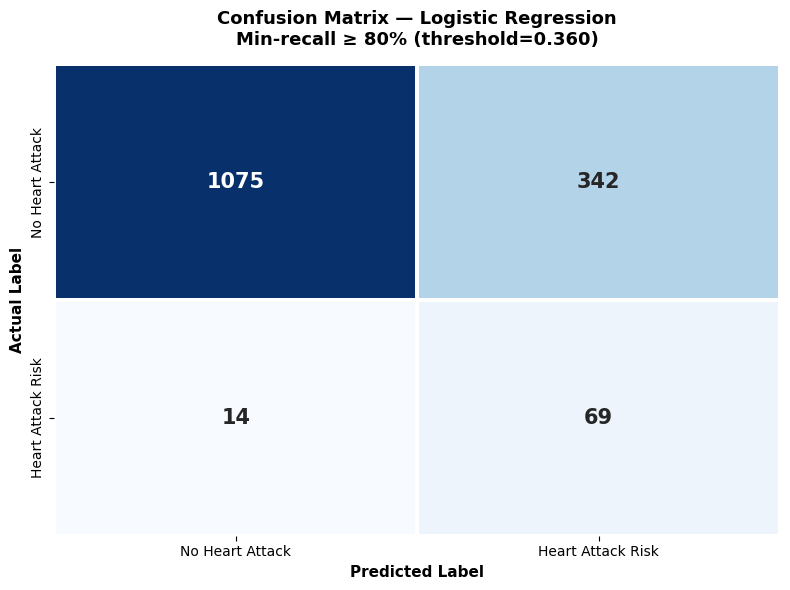

CONFUSION MATRIX RESULTS
True Negatives  (TN): 1075
False Positives (FP): 342
False Negatives (FN): 14  <- missed positive cases
True Positives  (TP): 69

Sensitivity (Recall): 0.8313
Specificity         : 0.7586

Insight:
- Correct predictions: 1144 out of 1500.
- False negatives: 14; these are positive cases the model missed and deserve special attention.
- False positives: 342; these are negative cases incorrectly flagged as positive.


In [81]:
# Calculate the confusion matrix at the selected operating threshold
cm = confusion_matrix(y_test_m, test_preds)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=1.5,
    linecolor="white",
    xticklabels=["No Heart Attack", "Heart Attack Risk"],
    yticklabels=["No Heart Attack", "Heart Attack Risk"],
    annot_kws={"size": 15, "weight": "bold"},
    ax=ax
)
ax.set_title(
    f"Confusion Matrix — {best_name}\n{point_label} (threshold={chosen_thresh:.3f})",
    fontsize=13, fontweight="bold", pad=14
)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold")
ax.set_ylabel("Actual Label", fontsize=11, fontweight="bold")
ax.tick_params(axis="both", labelsize=10)
plt.tight_layout()
plt.show()

print("CONFUSION MATRIX RESULTS")
print("=" * 42)
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}  <- missed positive cases")
print(f"True Positives  (TP): {tp}")

sensitivity = tp / (tp + fn + 1e-12)
specificity = tn / (tn + fp + 1e-12)
print(f"\nSensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity         : {specificity:.4f}")

print("\nInsight:")
print(f"- Correct predictions: {tn + tp} out of {cm.sum()}.")
print(f"- False negatives: {fn}; these are positive cases the model missed and deserve special attention.")
print(f"- False positives: {fp}; these are negative cases incorrectly flagged as positive.")


### 4.7 ROC & Precision-Recall Curves


In [82]:
# ROC and Precision-Recall — interactive Plotly panels
fpr, tpr, _ = roc_curve(y_test_m, test_probs)
prec, rec, _ = precision_recall_curve(y_test_m, test_probs)
fig = make_subplots(rows=1, cols=2, subplot_titles=("ROC Curve — Test Set", "Precision–Recall — Test Set"))
fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", name=f"{best_name} (AUC={roc_auc_score(y_test_m, test_probs):.3f})",
                         line=dict(color=RISK_GREEN, width=3)), row=1, col=1)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="Random baseline",
                         line=dict(color=RISK_YELLOW, dash="dash")), row=1, col=1)
fig.add_trace(go.Scatter(x=rec, y=prec, mode="lines", name=f"{best_name} (AP={average_precision_score(y_test_m, test_probs):.3f})",
                         line=dict(color=RISK_RED, width=3)), row=1, col=2)
fig.add_hline(y=float(np.mean(y_test_m)), line_dash="dash", line_color=RISK_YELLOW,
              annotation_text="Prevalence baseline", row=1, col=2)
fig.update_xaxes(title_text="False Positive Rate", row=1, col=1)
fig.update_yaxes(title_text="True Positive Rate (Recall)", row=1, col=1)
fig.update_xaxes(title_text="Recall", row=1, col=2)
fig.update_yaxes(title_text="Precision", row=1, col=2)
fig.update_layout(template="plotly_white", height=470, title="Discrimination performance on the untouched test set")
fig.show()


### 4.8 How to Adjust Recall for Clinical Use

| Goal | What to change |
|------|----------------|
| Catch more true cases (higher recall) | Increase `MIN_RECALL_TARGET` (e.g. 0.85) and keep `OPERATING_POINT = "min_recall"` |
| Balance precision & recall | Set `OPERATING_POINT = "f1"` |
| Moderate recall emphasis | Set `OPERATING_POINT = "f2"` |
| Stronger recall emphasis in F-beta | Increase `RECALL_PRIORITY_BETA` (e.g. 3.0) |

Re-run cells **4.3 → 4.6** after changing the parameters. The *Operating points* table in 4.5 records the test result of every option, so the trade-off (recall gained vs. extra patients flagged) is documented.

### 4.9 Save Best Model Artifact


In [83]:
os.makedirs("artifacts", exist_ok=True)

model_bundle = {
    "best_model_name": best_name,
    "model": best["model"],
    "best_params": best.get("params"),
    "threshold_f1": best["t_f1"],
    "threshold_f2": best["t_f2"],
    "threshold_min_recall": best["t_recall"],
    "chosen_operating_point": OPERATING_POINT,
    "chosen_threshold": chosen_thresh,
    "min_recall_target": MIN_RECALL_TARGET,
    "recall_priority_beta": RECALL_PRIORITY_BETA,
    "feature_names": feature_names_m,
    "val_leaderboard": val_df.to_dict(orient="records"),
}

joblib.dump(model_bundle, "artifacts/best_heart_attack_model.joblib")
print("Saved → artifacts/best_heart_attack_model.joblib")
print(f"Model: {best_name} | Operating threshold: {chosen_thresh:.4f} ({point_label})")

Saved → artifacts/best_heart_attack_model.joblib
Model: Logistic Regression | Operating threshold: 0.3596 (Min-recall ≥ 80%)


---
# 5. Unsupervised Learning — Patient Segmentation & Anomaly Detection

This section is fully separate from supervised learning and explores the data **without using `HeartAttackRisk` during unsupervised model fitting**.

**Goals:**
1. Discover natural patient subgroups (clustering)
2. Detect unusual patients (anomaly detection)
3. Engineer unsupervised features that may improve supervised models
4. Mine interpretable association rules linked to heart attack risk

**Important design rule:**  
All clustering and anomaly models are fit on the **processed training set** (`X_train_processed`) only; validation and test rows are merely transformed.  
No resampling is used anywhere in the notebook.

### 5.1 Preparing Data for Clustering

- Drop high-cardinality `State_*` one-hot columns (they distort distances).
- Drop `HeightInMeters` and `WeightInKilograms` (collinear with BMI).
- Use the processed training matrix (no resampling is used anywhere in this notebook).

In [84]:
feature_names = np.asarray(feature_names)

drop_mask = np.array([
    name.startswith("State_") or name in ["HeightInMeters", "WeightInKilograms"]
    for name in feature_names
])
keep_idx = np.where(~drop_mask)[0]
cluster_features = feature_names[keep_idx]

Xc_train = np.asarray(X_train_processed)[:, keep_idx]
Xc_val   = np.asarray(X_val_processed)[:, keep_idx]
Xc_test  = np.asarray(X_test_processed)[:, keep_idx]

print("Features before:", len(feature_names), "| after:", len(cluster_features))
print("Train for clustering:", Xc_train.shape)


Features before: 49 | after: 47
Train for clustering: (6999, 47)


### Unsupervised Visualization — PCA Cumulative Explained Variance

We keep the smallest number of principal components that explain at least **90%** of the variance.  
These components become the working space for clustering and visualization.

In [85]:
pca_full = PCA(random_state=RANDOM_STATE).fit(Xc_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.90) + 1)
print(f"Components needed for 90% variance: {n_comp}")

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=np.arange(1, len(cum_var) + 1),
    y=cum_var * 100,
    mode="lines+markers",
    line=dict(color="#264653")
))
fig.add_hline(y=90, line_dash="dash", line_color="#e76f51", annotation_text="90%")
fig.add_vline(x=n_comp, line_dash="dash", line_color="#6c757d")
fig.update_layout(
    title="PCA Cumulative Explained Variance",
    xaxis_title="Number of components",
    yaxis_title="Cumulative variance (%)",
    template="plotly_white",
    height=420
)
fig.show()

pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(Xc_train)
Z_train = pca.transform(Xc_train)
Z_val   = pca.transform(Xc_val)
Z_test  = pca.transform(Xc_test)
print("Z_train:", Z_train.shape)


Components needed for 90% variance: 14


Z_train: (6999, 14)


Working in this reduced space stabilizes distance-based methods (KMeans, GMM, LOF) and speeds up t-SNE.

### Unsupervised Visualization — Choosing k for KMeans

We evaluate k = 2…10 using four complementary metrics:
- **Inertia (Elbow)** — lower is better, look for a bend
- **Silhouette** — higher is better
- **Davies–Bouldin** — lower is better
- **Calinski–Harabasz** — higher is better

In [86]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_train)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(Z_train, km.labels_),
        "davies_bouldin": davies_bouldin_score(Z_train, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(Z_train, km.labels_),
    })
k_scores = pd.DataFrame(rows)
display(k_scores.round(3))

fig = make_subplots(
    rows=1, cols=4,
    subplot_titles=["Elbow (Inertia)", "Silhouette ↑", "Davies-Bouldin ↓", "Calinski-Harabasz ↑"]
)
colors = ["#264653", "#2a9d8f", "#e9c46a", "#e76f51"]
for i, col in enumerate(["inertia", "silhouette", "davies_bouldin", "calinski_harabasz"], 1):
    fig.add_trace(
        go.Scatter(x=k_scores["k"], y=k_scores[col], mode="lines+markers",
                   line=dict(color=colors[i-1]), marker=dict(size=8)),
        row=1, col=i
    )
fig.update_layout(height=400, showlegend=False, title="Choosing k for KMeans", template="plotly_white")
fig.show()


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,58659.944,0.412,0.920,7800.980
1,3,45415.108,0.282,1.245,6057.461
2,4,40604.690,0.207,1.534,4792.310
3,5,38275.162,0.194,1.662,3918.861
4,6,36038.417,0.157,1.737,3415.998
5,7,34475.715,0.154,1.815,3028.104
6,8,33318.151,0.142,1.933,2720.004
7,9,32401.885,0.125,2.006,2471.663
8,10,31625.140,0.117,2.010,2269.743


Final k should balance metric quality **and** clinical interpretability — not metrics alone.

### 5.4 Final KMeans

Silhouette alone picks k = 2, which only splits the patients into a young/healthy and an old/high-burden group.  
`BEST_K` is therefore chosen by the **average rank of silhouette, Davies–Bouldin and Calinski–Harabasz** among `k >= MIN_K` (default 3), so that the clusters are rich enough for clinical profiling. The best-silhouette k is still printed for reference.

In [87]:
MIN_K = 3
cand = k_scores[k_scores["k"] >= MIN_K].copy()
cand["rank_silhouette"] = cand["silhouette"].rank(ascending=False)
cand["rank_db"] = cand["davies_bouldin"].rank(ascending=True)
cand["rank_ch"] = cand["calinski_harabasz"].rank(ascending=False)
cand["avg_rank"] = cand[["rank_silhouette", "rank_db", "rank_ch"]].mean(axis=1)
display(cand[["k", "silhouette", "davies_bouldin", "calinski_harabasz", "avg_rank"]].round(3))

BEST_K = int(cand.sort_values(["avg_rank", "silhouette"], ascending=[True, False]).iloc[0]["k"])
print("k with best silhouette overall (reference):", int(k_scores.loc[k_scores["silhouette"].idxmax(), "k"]))
print(f"Chosen BEST_K (rank-aggregated, k >= {MIN_K}):", BEST_K)

kmeans = KMeans(n_clusters=BEST_K, n_init=20, random_state=RANDOM_STATE).fit(Z_train)

cl_train = kmeans.labels_
cl_val   = kmeans.predict(Z_val)
cl_test  = kmeans.predict(Z_test)

print(pd.Series(cl_train).value_counts().sort_index())

,k,silhouette,davies_bouldin,calinski_harabasz,avg_rank
1,3,0.282,1.245,6057.461,1.0
2,4,0.207,1.534,4792.310,2.0
3,5,0.194,1.662,3918.861,3.0
4,6,0.157,1.737,3415.998,4.0
5,7,0.154,1.815,3028.104,5.0
6,8,0.142,1.933,2720.004,6.0
7,9,0.125,2.006,2471.663,7.0
8,10,0.117,2.010,2269.743,8.0


k with best silhouette overall (reference): 2
Chosen BEST_K (rank-aggregated, k >= 3): 3
0    2583
1    2445
2    1971
Name: count, dtype: int64


### Unsupervised Visualization — Heart Attack Rate per Cluster

We attach cluster labels to the **raw** training rows and summarize demographics, comorbidities, and the heart-attack rate inside each group.

In [88]:
prof = X_train.copy()
prof["Cluster"] = cl_train
prof["HeartAttackRisk"] = np.asarray(y_train)

# age_order (section 1) and health_map (Figure 47) are reused - not redefined here
prof["AgeNum"] = prof["AgeCategory"].astype(str).map({a: i for i, a in enumerate(age_order)})
prof["HealthScore"] = prof["GeneralHealth"].map(health_map)

summary = prof.groupby("Cluster").agg(
    Size=("HeartAttackRisk", "size"),
    HeartAttackRate_pct=("HeartAttackRisk", lambda s: round(s.mean() * 100, 2)),
    AgeNum_mean=("AgeNum", "mean"),
    BMI_mean=("BMI", "mean"),
    HealthScore_mean=("HealthScore", "mean"),
    Male_pct=("Sex", lambda s: round((s == "Male").mean() * 100, 1)),
    Angina_pct=("HadAngina", lambda s: round(s.mean() * 100, 1)),
    Stroke_pct=("HadStroke", lambda s: round(s.mean() * 100, 1)),
    Diabetes_pct=("HasDiabetes", lambda s: round(s.mean() * 100, 1)),   # same binary definition as the EDA section
    COPD_pct=("HadCOPD", lambda s: round(s.mean() * 100, 1)),
    Arthritis_pct=("HadArthritis", lambda s: round(s.mean() * 100, 1)),
    DiffWalking_pct=("DifficultyWalking", lambda s: round(s.mean() * 100, 1)),
    CurrentSmoker_pct=("SmokerStatus", lambda s: round(s.str.contains("Current").mean() * 100, 1)),
).round(2)
display(summary)

overall = np.asarray(y_train).mean() * 100
fig = px.bar(
    summary.reset_index(), x="Cluster", y="HeartAttackRate_pct",
    text="HeartAttackRate_pct",
    title=f"Heart Attack Rate per Cluster (overall = {overall:.2f}%)",
    color="HeartAttackRate_pct", color_continuous_scale="Reds"
)
fig.add_hline(y=overall, line_dash="dash", annotation_text="overall")
fig.update_layout(coloraxis_showscale=False, template="plotly_white", height=420)
fig.show()

,Size,HeartAttackRate_pct,AgeNum_mean,BMI_mean,HealthScore_mean,Male_pct,Angina_pct,Stroke_pct,Diabetes_pct,COPD_pct,Arthritis_pct,DiffWalking_pct,CurrentSmoker_pct
Cluster,,,,,,,,,,,,,
0,2583,10.14,10.29,27.86,3.23,46.3,11.8,6.9,21.4,11.9,52.3,22.4,7.8
1,2445,4.66,6.66,29.71,3.47,47.6,4.9,3.7,16.2,7.4,34.1,15.0,16.0
2,1971,0.66,2.15,28.47,3.82,51.5,0.8,0.9,5.1,2.3,10.5,4.4,13.7


Even without using the label during fitting, structure in the feature space aligns with cardiovascular risk — a useful check on data quality and feature relevance.

### Unsupervised Visualization — Cluster Profile Heatmap

Each column is min–max scaled across clusters so that relative differences are visible on a common color scale.

In [89]:
num_cols = [
    "AgeNum_mean", "BMI_mean", "HealthScore_mean", "Male_pct", "Angina_pct", "Stroke_pct",
    "Diabetes_pct", "COPD_pct", "Arthritis_pct", "DiffWalking_pct", "CurrentSmoker_pct",
    "HeartAttackRate_pct"
]
heat = summary[num_cols]
heat_scaled = (heat - heat.min()) / (heat.max() - heat.min() + 1e-9)

fig = px.imshow(
    heat_scaled.T, text_auto=False, aspect="auto",
    color_continuous_scale="RdYlGn_r",
    labels=dict(x="Cluster", y="", color="relative level"),
    title="Cluster Profile Heatmap (0 = lowest cluster, 1 = highest cluster)"
)
fig.update_layout(height=520, template="plotly_white")
fig.show()


### Unsupervised Visualization — Clusters in PCA Space

In [91]:
vis = pd.DataFrame(Z_train[:, :2], columns=["PC1", "PC2"])
vis["Cluster"] = [cluster_names[c] for c in cl_train]
vis["HeartAttack"] = np.asarray(y_train).astype(str)

fig = px.scatter(
    vis, x="PC1", y="PC2", color="Cluster", opacity=0.55,
    title="Clusters in PCA space",
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(template="plotly_white", height=480)
fig.show()

fig = px.scatter(
    vis.sort_values("HeartAttack"),
    x="PC1", y="PC2", color="HeartAttack",
    color_discrete_map={"0": "#b0b0b0", "1": "#e63946"},
    opacity=0.7,
    title="Heart attack cases (red) in PCA space"
)
fig.update_layout(template="plotly_white", height=480)
fig.show()


### Unsupervised Visualization — t-SNE Projection

t-SNE is run on all positive cases plus a sample of negatives for readability and speed.

In [92]:
rng = np.random.RandomState(RANDOM_STATE)
pos_idx = np.where(np.asarray(y_train) == 1)[0]
neg_idx = rng.choice(np.where(np.asarray(y_train) == 0)[0], size=min(1500, (np.asarray(y_train) == 0).sum()), replace=False)
idx = np.concatenate([pos_idx, neg_idx])

tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
T = tsne.fit_transform(Z_train[idx])

tv = pd.DataFrame(T, columns=["tSNE1", "tSNE2"])
tv["Cluster"] = [cluster_names[c] for c in cl_train[idx]]
tv["HeartAttack"] = np.asarray(y_train)[idx].astype(str)

fig = px.scatter(
    tv, x="tSNE1", y="tSNE2", color="Cluster", symbol="HeartAttack",
    symbol_map={"0": "circle", "1": "x"},
    opacity=0.7,
    title="t-SNE (all positives + sample of negatives)",
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(template="plotly_white", height=500)
fig.show()


Unsupervised structure is informative as a feature source, not as a standalone diagnostic rule.

### Unsupervised Visualization — GMM BIC Curve & Algorithm Comparison

In [93]:
bic = []
for k in K_RANGE:
    gm_k = GaussianMixture(
        n_components=k, covariance_type="diag", n_init=3, random_state=RANDOM_STATE
    ).fit(Z_train)
    bic.append(gm_k.bic(Z_train))

fig = px.line(
    x=list(K_RANGE), y=bic, markers=True,
    title="GMM BIC (lower is better)",
    labels={"x": "components", "y": "BIC"}
)
fig.update_traces(line_color="#264653")
fig.update_layout(template="plotly_white", height=400)
fig.show()

print("GMM best components by BIC:", list(K_RANGE)[int(np.argmin(bic))])

gmm = GaussianMixture(
    n_components=BEST_K, covariance_type="diag", n_init=5, random_state=RANDOM_STATE
).fit(Z_train)
gmm_train = gmm.predict(Z_train)
print(f"GMM (k={BEST_K}) silhouette:", round(silhouette_score(Z_train, gmm_train), 3))

agg = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward").fit(Z_train)
print("Hierarchical silhouette:", round(silhouette_score(Z_train, agg.labels_), 3))
print("ARI (KMeans vs Hierarchical):", round(adjusted_rand_score(cl_train, agg.labels_), 3))

for name, lab in {"KMeans": cl_train, "GMM": gmm_train, "Hierarchical": agg.labels_}.items():
    rate = pd.Series(np.asarray(y_train)).groupby(lab).mean().mul(100).round(2)
    print(f"\n{name} — heart attack rate per cluster (%):")
    print(rate.to_string())


GMM best components by BIC: 9
GMM (k=3) silhouette: 0.252
Hierarchical silhouette: 0.238
ARI (KMeans vs Hierarchical): 0.547

KMeans — heart attack rate per cluster (%):
0    10.14
1     4.66
2     0.66

GMM — heart attack rate per cluster (%):
0    10.43
1     3.69
2     0.36

Hierarchical — heart attack rate per cluster (%):
0    8.50
1    0.86
2    4.14


### Unsupervised Visualization — Isolation Forest Anomaly Scores (Validation)

Anomaly models are trained **without the target**. The label is used only for evaluation.

In [94]:
iso = IsolationForest(
    n_estimators=300, contamination="auto", random_state=RANDOM_STATE, n_jobs=-1
)
iso.fit(Xc_train)

iso_train = -iso.score_samples(Xc_train)
iso_val   = -iso.score_samples(Xc_val)
iso_test  = -iso.score_samples(Xc_test)

lof = LocalOutlierFactor(n_neighbors=30, novelty=True, n_jobs=-1)
lof.fit(Z_train)
lof_train = -lof.score_samples(Z_train)
lof_val   = -lof.score_samples(Z_val)
lof_test  = -lof.score_samples(Z_test)

print("Validation ROC-AUC (anomaly score vs HeartAttackRisk):")
print("  IsolationForest:", round(roc_auc_score(y_val, iso_val), 3))
print("  LOF            :", round(roc_auc_score(y_val, lof_val), 3))
print("Validation PR-AUC (baseline = %.3f):" % np.mean(y_val))
print("  IsolationForest:", round(average_precision_score(y_val, iso_val), 3))
print("  LOF            :", round(average_precision_score(y_val, lof_val), 3))

fig = px.histogram(
    pd.DataFrame({"score": iso_val, "HeartAttack": np.asarray(y_val).astype(str)}),
    x="score", color="HeartAttack", barmode="overlay", opacity=0.6,
    histnorm="probability density",
    color_discrete_map={"0": "#888888", "1": "#e63946"},
    title="Isolation Forest score — validation set"
)
fig.update_layout(template="plotly_white", height=420)
fig.show()


Validation ROC-AUC (anomaly score vs HeartAttackRisk):
  IsolationForest: 0.745
  LOF            : 0.632
Validation PR-AUC (baseline = 0.055):
  IsolationForest: 0.201
  LOF            : 0.088


Anomaly scores are weak standalone predictors but can still add a useful continuous signal to supervised models.

### 5.9 Engineering Unsupervised Features for Supervised Models

Three families of features are derived from models fit only on the training data:

1. Cluster membership (one-hot)
2. Distance to each KMeans centroid
3. Anomaly scores (Isolation Forest + LOF)

They are appended to the training / validation / test matrices.

In [95]:
def make_unsup_features(X_full):
    X_full = np.asarray(X_full)
    Xc = X_full[:, keep_idx]
    Z = pca.transform(Xc)

    labels = kmeans.predict(Z)
    onehot = np.eye(BEST_K)[labels]
    dists = kmeans.transform(Z)
    iso_s = (-iso.score_samples(Xc)).reshape(-1, 1)
    lof_s = (-lof.score_samples(Z)).reshape(-1, 1)

    return np.hstack([onehot, dists, iso_s, lof_s])


unsup_names = (
    [f"cluster_{c}" for c in range(BEST_K)] +
    [f"dist_to_c{c}" for c in range(BEST_K)] +
    ["iso_score", "lof_score"]
)

U_train     = make_unsup_features(X_train_processed)
U_val       = make_unsup_features(X_val_processed)
U_test      = make_unsup_features(X_test_processed)

X_train_enh = np.hstack([np.asarray(X_train_processed), U_train])
X_val_enh   = np.hstack([np.asarray(X_val_processed),  U_val])
X_test_enh  = np.hstack([np.asarray(X_test_processed), U_test])
feature_names_enh = np.concatenate([feature_names, unsup_names])

print("Before:", np.asarray(X_train_processed).shape, "→ After:", X_train_enh.shape)

Before: (6999, 49) → After: (6999, 57)


### 5.10 Did Unsupervised Features Help?

We compare Logistic Regression and Random Forest **with and without** unsupervised features on the validation set (class-weighted, no resampling).  
Thresholds maximize **F2** (recall-oriented), consistent with the medical objective.  
**Decision rule:** the features are kept only if PR-AUC improves by more than +0.005 for *both* models.

In [96]:
def evaluate(model, Xtr, ytr, Xv, yv, threshold_grid=np.linspace(0.05, 0.95, 91)):
    model.fit(Xtr, ytr)
    p = model.predict_proba(Xv)[:, 1]
    f2s = [fbeta_score(yv, (p >= t).astype(int), beta=2) for t in threshold_grid]
    t_best = threshold_grid[int(np.argmax(f2s))]
    pred = (p >= t_best).astype(int)
    return {
        "ROC-AUC": roc_auc_score(yv, p),
        "PR-AUC": average_precision_score(yv, p),
        "Threshold": t_best,
        "Recall": recall_score(yv, pred),
        "Precision": precision_score(yv, pred, zero_division=0),
        "F2": fbeta_score(yv, pred, beta=2),
    }


models_unsup_check = {
    "LogReg": lambda: LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
    ),
}

results = []
for name, make in models_unsup_check.items():
    r0 = evaluate(make(), np.asarray(X_train_processed), np.asarray(y_train),
                  np.asarray(X_val_processed), y_val)
    r1 = evaluate(make(), X_train_enh, np.asarray(y_train), X_val_enh, y_val)
    results.append({"Model": name, "Features": "Baseline", **r0})
    results.append({"Model": name, "Features": "Baseline + Unsupervised", **r1})

display(pd.DataFrame(results).round(3))

,Model,Features,ROC-AUC,PR-AUC,Threshold,Recall,Precision,F2
0,LogReg,Baseline,0.880,0.380,0.72,0.590,0.368,0.527
1,LogReg,Baseline + Unsupervised,0.876,0.371,0.76,0.578,0.397,0.530
2,RandomForest,Baseline,0.874,0.329,0.37,0.735,0.219,0.499
3,RandomForest,Baseline + Unsupervised,0.869,0.354,0.43,0.687,0.237,0.497


In [97]:
# Automatic verdict (so the conclusion always matches the numbers of the current run)
res_df = pd.DataFrame(results)
verdicts = []
for m in res_df["Model"].unique():
    base = res_df[(res_df["Model"] == m) & (res_df["Features"] == "Baseline")].iloc[0]
    enh  = res_df[(res_df["Model"] == m) & (res_df["Features"] != "Baseline")].iloc[0]
    d = enh["PR-AUC"] - base["PR-AUC"]
    verdicts.append(d)
    word = "IMPROVED" if d > 0.005 else ("WORSE" if d < -0.005 else "NO MATERIAL CHANGE")
    print(f"{m:13s}: PR-AUC {base['PR-AUC']:.4f} -> {enh['PR-AUC']:.4f} (delta {d:+.4f})  => {word}")

UNSUP_FEATURES_HELP = all(d > 0.005 for d in verdicts)
print("\nDecision:", "keep unsupervised features in the supervised pipeline" if UNSUP_FEATURES_HELP
      else "do NOT add them to the supervised models (section 4 stays on the baseline features); "
           "keep clustering / anomaly scores / association rules for interpretation only")

LogReg       : PR-AUC 0.3797 -> 0.3709 (delta -0.0088)  => WORSE
RandomForest : PR-AUC 0.3290 -> 0.3535 (delta +0.0246)  => IMPROVED

Decision: do NOT add them to the supervised models (section 4 stays on the baseline features); keep clustering / anomaly scores / association rules for interpretation only


**Conclusion (5.10):** The decision printed above is the outcome of the rule stated in 5.10. If the unsupervised features do not improve PR-AUC for both models, they add dimensionality and (for LOF / Isolation Forest scores computed on training points) a small in-sample optimism without adding signal, so the final models in Section 4 keep the baseline features. The unsupervised analysis remains valuable for **interpretation**: patient segments with their heart-attack rates (see the separately labeled unsupervised visualizations) and the association rules below.

### 5.11 Association Rule Mining (Apriori)

We mine interpretable combinations associated with `HeartAttackRisk=Yes`.

**Leakage-safe setup:** rules are learned only from the original `X_train` / `y_train`.  
Validation is used only to score rules. The test set stays untouched.  
Apriori and FP-Growth return identical itemsets; FP-Growth took ~140 s on this matrix, so only Apriori runs by default (`RUN_FPGROWTH_BENCHMARK`).

In [98]:
AR_MIN_SUPPORT = 0.003
AR_MIN_CONFIDENCE = 0.10
AR_MAX_LEN = 3

AR_CANDIDATE_COLS = [
    "AgeCategory", "Sex", "GeneralHealth", "BMI", "SmokerStatus",
    "HadAngina", "HadStroke", "HadDiabetes", "HadCOPD", "HadArthritis",
    "DifficultyWalking", "HadKidneyDisease", "HadSkinCancer"
]


def make_ar_transactions(X, y=None, include_target=False):
    d = X.copy().reset_index(drop=True)
    items = pd.DataFrame(index=d.index)
    for col in AR_CANDIDATE_COLS:
        if col not in d.columns:
            continue
        s = d[col]
        if col == "BMI":
            bmi_labels = ["Underweight", "Normal", "Overweight", "Obesity_I", "Obesity_II", "Obesity_III"]
            b = pd.cut(
                pd.to_numeric(s, errors="coerce"),
                bins=[-np.inf, 18.5, 25, 30, 35, 40, np.inf],
                labels=bmi_labels
            ).astype("object")
            for lvl in bmi_labels:                       # one boolean item per BMI band
                items[f"BMI={lvl}"] = (b == lvl).to_numpy()
        else:
            vals = s.astype("object")
            for value in vals.dropna().unique():
                name = f"{col}={value}"
                items[name] = vals.eq(value).fillna(False).to_numpy()
    if include_target:
        yy = np.asarray(y).reshape(-1)
        items["HeartAttackRisk=Yes"] = (yy == 1)
        items["HeartAttackRisk=No"] = (yy == 0)
    items = items.loc[:, (items.sum(axis=0) > 0) & (items.sum(axis=0) < len(items))]
    return items.astype(bool)


ar_train = make_ar_transactions(X_train, y_train, include_target=True)
ar_val = make_ar_transactions(X_val, include_target=False)
print("Transaction matrix:", ar_train.shape, "| validation:", ar_val.shape)
print("Positive target prevalence:", round(np.mean(y_train), 4))

bmi_items = [c for c in ar_train.columns if c.startswith("BMI=")]
print("BMI items in the transaction matrix:", bmi_items)
assert len(bmi_items) > 0, "BMI items are missing from the association-rule matrix"

Transaction matrix: (6999, 50) | validation: (1501, 48)
Positive target prevalence: 0.0556
BMI items in the transaction matrix: ['BMI=Underweight', 'BMI=Normal', 'BMI=Overweight', 'BMI=Obesity_I', 'BMI=Obesity_II', 'BMI=Obesity_III']


In [99]:
RUN_FPGROWTH_BENCHMARK = False   # True -> also time FP-Growth (slow on this matrix)

t0 = time.perf_counter()
freq_ap = apriori(ar_train, min_support=AR_MIN_SUPPORT, use_colnames=True, max_len=AR_MAX_LEN)
ap_seconds = time.perf_counter() - t0
print(f"Apriori: {len(freq_ap)} itemsets in {ap_seconds:.2f}s")

if RUN_FPGROWTH_BENCHMARK:
    t0 = time.perf_counter()
    freq_fp = fpgrowth(ar_train, min_support=AR_MIN_SUPPORT, use_colnames=True, max_len=AR_MAX_LEN)
    print(f"FP-Growth: {len(freq_fp)} itemsets in {time.perf_counter() - t0:.2f}s")

rules_all = association_rules(freq_ap, metric="confidence", min_threshold=AR_MIN_CONFIDENCE)
rules_heart = rules_all[
    rules_all["consequents"].apply(lambda z: z == frozenset({"HeartAttackRisk=Yes"}))
].copy()

if len(rules_heart):
    rules_heart = rules_heart.sort_values(["lift", "confidence", "support"], ascending=False)
    display(rules_heart[["antecedents", "consequents", "support", "confidence", "lift", "leverage", "conviction"]].head(30))
    n_bmi = rules_heart["antecedents"].apply(lambda a: any(i.startswith("BMI=") for i in a)).sum()
    print(f"Rules whose antecedent contains a BMI band: {n_bmi}")
else:
    print("No positive-outcome rules at current thresholds. Try lowering AR_MIN_SUPPORT (e.g. 0.001).")

Apriori: 8888 itemsets in 0.26s


,antecedents,consequents,support,confidence,lift,leverage,conviction
24087,"(HadAngina=1, SmokerStatus=Current smoker - no...",(HeartAttackRisk=Yes),0.005715,0.689655,12.408474,0.005255,3.043133
26279,"(HadAngina=1, HadStroke=1)",(HeartAttackRisk=Yes),0.007144,0.675676,12.156951,0.006556,2.911964
26575,"(HadAngina=1, HadKidneyDisease=1)",(HeartAttackRisk=Yes),0.006287,0.656716,11.815831,0.005755,2.751138
20200,"(HadAngina=1, GeneralHealth=Poor)",(HeartAttackRisk=Yes),0.005715,0.606061,10.904417,0.005191,2.397375
26442,"(HadAngina=1, HadCOPD=1)",(HeartAttackRisk=Yes),0.009144,0.587156,10.564279,0.008279,2.287597
26370,"(HadAngina=1, HadDiabetes=Yes)",(HeartAttackRisk=Yes),0.013002,0.587097,10.563214,0.011771,2.287269
26545,"(HadAngina=1, DifficultyWalking=1)",(HeartAttackRisk=Yes),0.015288,0.584699,10.520081,0.013835,2.274065
22591,"(HadAngina=1, BMI=Obesity_I)",(HeartAttackRisk=Yes),0.008001,0.583333,10.495501,0.007239,2.266610
17508,"(GeneralHealth=Fair, HadAngina=1)",(HeartAttackRisk=Yes),0.010859,0.575758,10.359196,0.009810,2.226134
8686,"(HadAngina=1, AgeCategory=Age 75 to 79)",(HeartAttackRisk=Yes),0.004572,0.571429,10.281307,0.004127,2.203648


Rules whose antecedent contains a BMI band: 24


In [100]:
def score_with_association_rules(X_raw, rules, fallback):
    if rules is None or rules.empty:
        return np.full(len(X_raw), float(fallback)), np.zeros(len(X_raw), dtype=bool)
    X_items = make_ar_transactions(X_raw, include_target=False)
    rule_list = []
    for _, r in rules.iterrows():
        ant = list(r["antecedents"])
        if all(item in X_items.columns for item in ant):
            rule_list.append((ant, float(r["confidence"])))
    scores = np.full(len(X_items), float(fallback))
    matched_any = np.zeros(len(X_items), dtype=bool)
    for ant, confidence in rule_list:
        matched = X_items[ant].all(axis=1).to_numpy()
        scores[matched] = np.maximum(scores[matched], confidence)
        matched_any |= matched
    return scores, matched_any


ar_val_score, ar_val_covered = score_with_association_rules(X_val, rules_heart, np.mean(y_train))
y_val_arr = np.asarray(y_val).astype(int)

if len(np.unique(y_val_arr)) == 2 and len(rules_heart):
    ar_thresholds = np.linspace(0.01, 0.99, 99)
    ar_f2 = [fbeta_score(y_val_arr, (ar_val_score >= t).astype(int), beta=2, zero_division=0) for t in ar_thresholds]
    ar_best_t = float(ar_thresholds[int(np.argmax(ar_f2))])
    ar_pred = (ar_val_score >= ar_best_t).astype(int)
    ar_comparison_row = {
        "Model": "Association Rules",
        "Features": "Apriori rules",
        "ROC-AUC": roc_auc_score(y_val_arr, ar_val_score),
        "PR-AUC": average_precision_score(y_val_arr, ar_val_score),
        "Threshold": ar_best_t,
        "Recall": recall_score(y_val_arr, ar_pred, zero_division=0),
        "Precision": precision_score(y_val_arr, ar_pred, zero_division=0),
        "F2": fbeta_score(y_val_arr, ar_pred, beta=2, zero_division=0),
    }
    comparison = pd.DataFrame(results + [ar_comparison_row])
    display(comparison.round(3).sort_values("PR-AUC", ascending=False))
    print("Rule coverage:", round(ar_val_covered.mean(), 3))
else:
    print("Could not evaluate association-rule score on validation.")
print("Positive rules:", len(rules_heart), "| validation coverage:", round(ar_val_covered.mean(), 3))

,Model,Features,ROC-AUC,PR-AUC,Threshold,Recall,Precision,F2
0,LogReg,Baseline,0.880,0.380,0.72,0.590,0.368,0.527
1,LogReg,Baseline + Unsupervised,0.876,0.371,0.76,0.578,0.397,0.530
3,RandomForest,Baseline + Unsupervised,0.869,0.354,0.43,0.687,0.237,0.497
4,Association Rules,Apriori rules,0.841,0.336,0.28,0.614,0.252,0.478
2,RandomForest,Baseline,0.874,0.329,0.37,0.735,0.219,0.499


Rule coverage: 0.644
Positive rules: 195 | validation coverage: 0.644


**How to read the rules**
- **Support** — how common the full pattern is
- **Confidence** — P(heart attack | antecedent)
- **Lift > 1** — pattern raises risk above baseline prevalence

These are associations, not causal effects. Their main value is interpretability alongside supervised models.


### 5.12 Unsupervised Models Comparison (charts)

Only unsupervised methods are compared here, in three groups:
1. **Clustering** — KMeans vs GMM vs Hierarchical (internal quality metrics + how well clusters separate heart-attack risk)
2. **Anomaly detection** — Isolation Forest vs LOF (how well the anomaly score ranks heart-attack cases on validation)
3. **Added value for supervised models** — baseline features vs baseline + unsupervised features

In [101]:
# ---------- 1) Clustering comparison ----------
clusterers = {"KMeans": cl_train, "GMM": gmm_train, "Hierarchical": agg.labels_}
y_tr_arr = np.asarray(y_train)
clu_rows = []
for name, lab in clusterers.items():
    rates = pd.Series(y_tr_arr).groupby(lab).mean() * 100
    clu_rows.append({
        "Method": name,
        "Silhouette (higher)": silhouette_score(Z_train, lab),
        "Davies-Bouldin (lower)": davies_bouldin_score(Z_train, lab),
        "Calinski-Harabasz (higher)": calinski_harabasz_score(Z_train, lab),
        "Risk spread (max-min HA rate, %)": rates.max() - rates.min(),
    })
clu_df = pd.DataFrame(clu_rows).set_index("Method")
display(clu_df.round(3))
fig = make_subplots(rows=2, cols=2, subplot_titles=list(clu_df.columns))
for j, col in enumerate(clu_df.columns):
    row, coln = divmod(j, 2)
    # Normalize each metric only for visual comparison; raw values remain in the table.
    vals = clu_df[col].astype(float)
    norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-9)
    # Davies-Bouldin is better when lower, so reverse its visual direction.
    if "Davies" in col: norm = 1 - norm
    colors = [RISK_RED if v == norm.max() else RISK_GREEN if v == norm.min() else RISK_YELLOW for v in norm]
    fig.add_trace(go.Bar(x=clu_df.index, y=vals, marker_color=colors, text=vals.round(3), textposition="outside",
                         name=col, showlegend=False), row=row+1, col=coln+1)
    fig.update_xaxes(tickangle=-15, row=row+1, col=coln+1)
fig.update_layout(title=f"Clustering methods comparison (k={BEST_K}) — colors reflect relative metric quality", height=700,
                  template="plotly_white")
fig.show()


,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),"Risk spread (max-min HA rate, %)"
Method,,,,
KMeans,0.282,1.245,6057.461,9.484
GMM,0.252,1.139,4962.072,10.072
Hierarchical,0.238,1.354,5129.796,7.639


Compare the displayed values to identify the highest and lowest groups. A higher `HeartAttackRisk` rate indicates a stronger association within this sample; it does not establish causation or provide an individual diagnosis.


In [102]:
# ---------- 2) Anomaly-detection comparison (validation set) ----------
anom_scores = {"Isolation Forest": iso_val, "LOF": lof_val}
y_val_arr_ = np.asarray(y_val)
anom_df = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_val_arr_, s), "PR-AUC": average_precision_score(y_val_arr_, s)}
    for name, s in anom_scores.items()
}).T
display(anom_df.round(4))
fig = make_subplots(rows=1, cols=3, subplot_titles=("Ranking metrics", "ROC — validation", "Precision–Recall — validation"))
fig.add_trace(go.Bar(x=anom_df.index, y=anom_df["ROC-AUC"], name="ROC-AUC", marker_color=RISK_GREEN), row=1, col=1)
fig.add_trace(go.Bar(x=anom_df.index, y=anom_df["PR-AUC"], name="PR-AUC", marker_color=RISK_YELLOW), row=1, col=1)
for name, scores in anom_scores.items():
    fpr, tpr, _ = roc_curve(y_val_arr_, scores)
    p, r, _ = precision_recall_curve(y_val_arr_, scores)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", name=f"{name} ROC"), row=1, col=2)
    fig.add_trace(go.Scatter(x=r, y=p, mode="lines", name=f"{name} PR"), row=1, col=3)
fig.add_trace(go.Scatter(x=[0,1], y=[0,1], mode="lines", name="Chance", line=dict(dash="dash", color=RISK_YELLOW)), row=1, col=2)
fig.add_hline(y=float(y_val_arr_.mean()), line_dash="dash", line_color=RISK_YELLOW, row=1, col=3)
fig.update_layout(title="Anomaly detection comparison (validation)", template="plotly_white", height=470)
fig.update_xaxes(title_text="False Positive Rate", row=1, col=2)
fig.update_yaxes(title_text="True Positive Rate", row=1, col=2)
fig.update_xaxes(title_text="Recall", row=1, col=3)
fig.update_yaxes(title_text="Precision", row=1, col=3)
fig.show()


,ROC-AUC,PR-AUC
Isolation Forest,0.7450,0.2007
LOF,0.6318,0.0880


Compare the displayed values to identify the strongest and weakest anomaly-ranking results. These metrics describe validation-set performance and should not be interpreted as individual diagnoses.


In [103]:
# ---------- 3) Do unsupervised features add value? (from 5.10) ----------
feat_df = pd.DataFrame(results)
metrics_to_plot = ["PR-AUC", "ROC-AUC", "Recall", "F2"]
fig = make_subplots(rows=2, cols=2, subplot_titles=metrics_to_plot)
for j, metric in enumerate(metrics_to_plot):
    piv = feat_df.pivot(index="Model", columns="Features", values=metric)[["Baseline", "Baseline + Unsupervised"]]
    row, col = divmod(j, 2)
    for feature_set, color in [("Baseline", "#7A8793"), ("Baseline + Unsupervised", RISK_GREEN)]:
        fig.add_trace(go.Bar(x=piv.index, y=piv[feature_set], name=feature_set,
                             marker_color=color, showlegend=(j == 0)), row=row+1, col=col+1)
fig.update_layout(title="Baseline vs baseline + unsupervised features (validation)", barmode="group",
                  template="plotly_white", height=650)
fig.update_xaxes(tickangle=-15)
fig.show()


### 5.13 Save Unsupervised Artifacts

Saved objects can be reused by the supervised pipeline or by teammates without re-running clustering.

In [104]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump({
    "keep_idx": keep_idx,
    "pca": pca,
    "kmeans": kmeans,
    "iso": iso,
    "lof": lof,
    "best_k": BEST_K,
    "cluster_names": cluster_names,
    "unsup_names": unsup_names,
    "association_rules_heart": rules_heart if "rules_heart" in dir() else None,
    "association_rule_min_support": AR_MIN_SUPPORT,
    "association_rule_min_confidence": AR_MIN_CONFIDENCE,
}, "artifacts/unsupervised_models.joblib")

joblib.dump({
    "X_train": X_train_enh,
    "X_val": X_val_enh,
    "X_test": X_test_enh,
    "y_train": np.asarray(y_train),
    "y_val": np.asarray(y_val),
    "y_test": np.asarray(y_test),
    "feature_names": feature_names_enh,
}, "artifacts/processed_data_with_unsup.joblib")

summary.to_csv("artifacts/cluster_profile.csv")
print("Unsupervised artifacts saved.")
print(" - artifacts/unsupervised_models.joblib")
print(" - artifacts/processed_data_with_unsup.joblib")
print(" - artifacts/cluster_profile.csv")

Unsupervised artifacts saved.
 - artifacts/unsupervised_models.joblib
 - artifacts/processed_data_with_unsup.joblib
 - artifacts/cluster_profile.csv


---
# 6. Neural Network (Keras MLP)

A feed-forward network on the same processed features as Section 4.

- **Imbalance:** class weights in `fit` (same positive weight as the other models), no resampling
- **Regularization:** L2 + Dropout + BatchNorm, `EarlyStopping` on validation PR-AUC
- **Tuning:** small grid over layer sizes, dropout and learning rate; the configuration with the best **validation PR-AUC** is kept
- Thresholds (F1 / F2 / min-recall) are chosen on validation, exactly as for the other models; the test set is used once at the end

In [105]:
def build_mlp(input_dim, units1=128, units2=64, dropout=0.3, lr=1e-3, l2=1e-4):
    reg = keras.regularizers.l2(l2)
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(units1, activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(dropout),
        layers.Dense(units2, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(curve="PR", name="pr_auc")],
    )
    return model


nn_results, nn_best = [], None
if not HAS_TF:
    print("TensorFlow is not available - neural-network section skipped.")
else:
    keras.utils.set_random_seed(RANDOM_STATE)
    Xn_train = np.asarray(X_train_m, dtype="float32")
    Xn_val   = np.asarray(X_val_m, dtype="float32")
    Xn_test  = np.asarray(X_test_m, dtype="float32")
    yn_train = np.asarray(y_train_m, dtype="float32")
    yn_val   = np.asarray(y_val_m, dtype="float32")
    class_weight = {0: 1.0, 1: float(SCALE_POS_WEIGHT)}

    nn_grid = [
        dict(units1=u1, units2=u2, dropout=d, lr=lr)
        for (u1, u2) in [(64, 32), (128, 64), (256, 128)]
        for d in [0.2, 0.4]
        for lr in [1e-3, 3e-4]
    ]

    for cfg in nn_grid:
        keras.backend.clear_session()
        keras.utils.set_random_seed(RANDOM_STATE)
        model = build_mlp(Xn_train.shape[1], **cfg)
        stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10, restore_best_weights=True)
        hist = model.fit(Xn_train, yn_train, validation_data=(Xn_val, yn_val), epochs=100, batch_size=256,
                         class_weight=class_weight, callbacks=[stop], verbose=0)
        val_pr = max(hist.history["val_pr_auc"])
        nn_results.append({**cfg, "epochs": len(hist.history["loss"]), "val_pr_auc": round(val_pr, 4)})
        if nn_best is None or val_pr > nn_best["val_pr_auc"]:
            nn_best = {"cfg": cfg, "model": model, "history": hist.history, "val_pr_auc": val_pr}
        print(f"{cfg} -> val PR-AUC {val_pr:.4f} ({len(hist.history['loss'])} epochs)")

    print("\n=== Neural network grid (sorted) ===")
    display(pd.DataFrame(nn_results).sort_values("val_pr_auc", ascending=False).reset_index(drop=True))
    print("Best configuration:", nn_best["cfg"])

{'units1': 64, 'units2': 32, 'dropout': 0.2, 'lr': 0.001} -> val PR-AUC 0.3523 (32 epochs)
{'units1': 64, 'units2': 32, 'dropout': 0.2, 'lr': 0.0003} -> val PR-AUC 0.3437 (49 epochs)
{'units1': 64, 'units2': 32, 'dropout': 0.4, 'lr': 0.001} -> val PR-AUC 0.3784 (66 epochs)
{'units1': 64, 'units2': 32, 'dropout': 0.4, 'lr': 0.0003} -> val PR-AUC 0.3402 (62 epochs)
{'units1': 128, 'units2': 64, 'dropout': 0.2, 'lr': 0.001} -> val PR-AUC 0.4033 (21 epochs)
{'units1': 128, 'units2': 64, 'dropout': 0.2, 'lr': 0.0003} -> val PR-AUC 0.4031 (34 epochs)
{'units1': 128, 'units2': 64, 'dropout': 0.4, 'lr': 0.001} -> val PR-AUC 0.4088 (30 epochs)
{'units1': 128, 'units2': 64, 'dropout': 0.4, 'lr': 0.0003} -> val PR-AUC 0.3941 (32 epochs)
{'units1': 256, 'units2': 128, 'dropout': 0.2, 'lr': 0.001} -> val PR-AUC 0.3823 (14 epochs)
{'units1': 256, 'units2': 128, 'dropout': 0.2, 'lr': 0.0003} -> val PR-AUC 0.3707 (17 epochs)
{'units1': 256, 'units2': 128, 'dropout': 0.4, 'lr': 0.001} -> val PR-AUC 0.3

,units1,units2,dropout,lr,epochs,val_pr_auc
0,128,64,0.4,0.0010,30,0.4088
1,128,64,0.2,0.0010,21,0.4033
2,128,64,0.2,0.0003,34,0.4031
3,256,128,0.4,0.0010,13,0.3980
4,128,64,0.4,0.0003,32,0.3941
5,256,128,0.4,0.0003,29,0.3924
6,256,128,0.2,0.0010,14,0.3823
7,64,32,0.4,0.0010,66,0.3784
8,256,128,0.2,0.0003,17,0.3707
9,64,32,0.2,0.0010,32,0.3523


Best configuration: {'units1': 128, 'units2': 64, 'dropout': 0.4, 'lr': 0.001}


In [106]:
if nn_best is not None:
    h = nn_best["history"]
    epochs = list(range(1, len(h["loss"]) + 1))
    fig = make_subplots(rows=1, cols=2, subplot_titles=("Loss", "PR-AUC"))
    fig.add_trace(go.Scatter(x=epochs, y=h["loss"], mode="lines", name="Train loss", line=dict(color="#457B9D")), row=1, col=1)
    fig.add_trace(go.Scatter(x=epochs, y=h["val_loss"], mode="lines", name="Validation loss", line=dict(color=RISK_RED)), row=1, col=1)
    fig.add_trace(go.Scatter(x=epochs, y=h["pr_auc"], mode="lines", name="Train PR-AUC", line=dict(color="#457B9D")), row=1, col=2)
    fig.add_trace(go.Scatter(x=epochs, y=h["val_pr_auc"], mode="lines", name="Validation PR-AUC", line=dict(color=RISK_GREEN)), row=1, col=2)
    fig.update_layout(title="Neural network learning curves", template="plotly_white", height=450)
    fig.update_xaxes(title_text="Epoch")
    fig.show()

    nn_model = nn_best["model"]
    nn_train_probs = nn_model.predict(Xn_train, verbose=0).ravel()
    nn_val_probs   = nn_model.predict(Xn_val, verbose=0).ravel()
    nn_test_probs  = nn_model.predict(Xn_test, verbose=0).ravel()
    print(f"Train PR-AUC {average_precision_score(y_train_m, nn_train_probs):.4f} | "
          f"Val PR-AUC {average_precision_score(y_val_m, nn_val_probs):.4f}  (gap = over-fitting check)")
    nn_model.save("artifacts/neural_network.keras")


Train PR-AUC 0.5670 | Val PR-AUC 0.4107  (gap = over-fitting check)


---
# 7. Supervised Models Comparison

All supervised models (including the Stacking ensemble and neural network when available) are compared here. The unsupervised models are compared separately in section 5.12.

### 7.1 Test-set comparison (tables + charts)

Model selection used validation PR-AUC only. Test numbers are reported once, with every threshold fixed on the validation set.

In [107]:
# ---- 7.1 Supervised comparison: table ----
all_probs = {n: (v["train_probs"], v["val_probs"], v["model"].predict_proba(X_test_m)[:, 1]) for n, v in fitted.items()}
if nn_best is not None:
    all_probs["Neural Network (MLP)"] = (nn_train_probs, nn_val_probs, nn_test_probs)

sup_rows = []
for name, (trp, vp, tp_) in all_probs.items():
    t_min = threshold_for_min_recall(y_val_m, vp, min_recall=MIN_RECALL_TARGET)
    t_f2_, _ = find_optimal_threshold(y_val_m, vp, beta=RECALL_PRIORITY_BETA)
    row = {"Model": name,
           "Train PR-AUC": average_precision_score(y_train_m, trp),
           "Val PR-AUC": average_precision_score(y_val_m, vp),
           "Test PR-AUC": average_precision_score(y_test_m, tp_),
           "Test ROC-AUC": roc_auc_score(y_test_m, tp_)}
    for label, th in [(f"F{RECALL_PRIORITY_BETA:g}", t_f2_), ("MinRecall", t_min)]:
        pr = (tp_ >= th).astype(int)
        tn_, fp_, fn_, tp2 = confusion_matrix(y_test_m, pr).ravel()
        row[f"{label} recall"] = tp2 / (tp2 + fn_)
        row[f"{label} precision"] = tp2 / max(tp2 + fp_, 1)
        row[f"{label} missed"] = int(fn_)
    sup_rows.append(row)

sup_table = pd.DataFrame(sup_rows).sort_values("Val PR-AUC", ascending=False).reset_index(drop=True)
display(sup_table.round(4))
sup_table.to_csv("artifacts/supervised_model_comparison.csv", index=False)

,Model,Train PR-AUC,Val PR-AUC,Test PR-AUC,Test ROC-AUC,F2 recall,F2 precision,F2 missed,MinRecall recall,MinRecall precision,MinRecall missed
0,Neural Network (MLP),0.5670,0.4107,0.4412,0.8613,0.6145,0.3493,32,0.8072,0.1791,16
1,Logistic Regression,0.5084,0.3790,0.4066,0.8707,0.5542,0.3217,37,0.8313,0.1679,14
2,LightGBM,0.5566,0.3675,0.3966,0.8705,0.6145,0.3129,32,0.8313,0.1721,14
3,Stacking Ensemble (Meta-Learner),0.5868,0.3618,0.4098,0.8732,0.5663,0.3333,36,0.8434,0.1683,13
4,XGBoost,0.5680,0.3604,0.4150,0.8717,0.6386,0.3312,30,0.8313,0.1624,14
5,CatBoost,0.5729,0.3595,0.4140,0.8718,0.6747,0.2772,27,0.8313,0.1635,14
6,Random Forest,0.6034,0.3482,0.4011,0.8710,0.6024,0.2941,33,0.8313,0.1700,14


In [108]:
# ---- 7.1 Supervised comparison: charts ----
fig = make_subplots(rows=1, cols=3, subplot_titles=(
    "PR-AUC: train vs validation vs test", "Test ROC-AUC", f"Test recall / precision at min-recall {MIN_RECALL_TARGET:.0%}"))
for col, name in [("Train PR-AUC", "Train"), ("Val PR-AUC", "Validation"), ("Test PR-AUC", "Test")]:
    fig.add_trace(go.Bar(x=sup_table["Model"], y=sup_table[col], name=name), row=1, col=1)
fig.add_trace(go.Bar(x=sup_table["Model"], y=sup_table["Test ROC-AUC"], name="Test ROC-AUC", marker_color="#2a9d8f", showlegend=False), row=1, col=2)
fig.add_trace(go.Bar(x=sup_table["Model"], y=sup_table["MinRecall recall"], name="Recall", marker_color="#e76f51"), row=1, col=3)
fig.add_trace(go.Bar(x=sup_table["Model"], y=sup_table["MinRecall precision"], name="Precision", marker_color="#264653"), row=1, col=3)
fig.update_layout(height=480, barmode="group", title="Supervised models comparison", template="plotly_white")
fig.update_xaxes(tickangle=-30)
fig.show()

# ROC and PR curves of all models on the test set — Plotly
fig = make_subplots(rows=1, cols=2, subplot_titles=("ROC curves — test", "Precision–Recall curves — test"))
for name, (_, _, probs_) in all_probs.items():
    fpr, tpr, _ = roc_curve(y_test_m, probs_)
    p_, r_, _ = precision_recall_curve(y_test_m, probs_)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines",
                             name=f"{name} (AUC={roc_auc_score(y_test_m, probs_):.3f})"), row=1, col=1)
    fig.add_trace(go.Scatter(x=r_, y=p_, mode="lines",
                             name=f"{name} (AP={average_precision_score(y_test_m, probs_):.3f})"), row=1, col=2)
fig.add_trace(go.Scatter(x=[0,1], y=[0,1], mode="lines", name="Chance baseline",
                         line=dict(color=RISK_YELLOW, dash="dash")), row=1, col=1)
fig.add_hline(y=float(np.mean(y_test_m)), line_dash="dash", line_color=RISK_YELLOW,
              annotation_text="Prevalence", row=1, col=2)
fig.update_layout(title="All supervised models — held-out test set", template="plotly_white", height=520)
fig.update_xaxes(title_text="False Positive Rate", row=1, col=1)
fig.update_yaxes(title_text="True Positive Rate", row=1, col=1)
fig.update_xaxes(title_text="Recall", row=1, col=2)
fig.update_yaxes(title_text="Precision", row=1, col=2)
fig.show()


---
## End of Notebook

Artifacts written to `artifacts/`: preprocessor, processed arrays, best supervised model bundle (`best_heart_attack_model.joblib`, same keys as before), unsupervised models, neural network and the final comparison table.

---
# 8. LLM Chat Assistant — Ask Questions A Medical Question

In [1]:

# ============================================================
# GENERAL HEALTH AI CHAT ASSISTANT
# Powered by Google Gemini
# Free-tier compatible model choices
# ============================================================

import time
from getpass import getpass
from google import genai
from google.genai import types

# ============================================================
# 1. API CONFIGURATION
# ============================================================

print("=" * 65)
print("GOOGLE GEMINI HEALTH ASSISTANT")
print("=" * 65)

GEMINI_API_KEY = getpass(
    "Enter your Google Gemini API Key: "
).strip()

if not GEMINI_API_KEY:
    raise ValueError("Gemini API Key cannot be empty.")

client = genai.Client(api_key=GEMINI_API_KEY)

# Primary model and fallback models
GEMINI_MODELS = [
    "gemini-3.5-flash-lite",
    "gemini-2.5-flash-lite"
]

print("\nGemini client initialized successfully.")

# ============================================================
# 2. SYSTEM INSTRUCTIONS
# ============================================================

SYSTEM_PROMPT = """
You are a knowledgeable, friendly, and responsible
GENERAL HEALTH AI ASSISTANT powered by Google Gemini.

YOUR ROLE:
Provide reliable general health information and explain
medical topics in a clear and understandable way.

HEALTH TOPICS:
1. Cardiovascular health and heart diseases.
2. Diabetes and blood sugar.
3. Blood pressure and cholesterol.
4. Nutrition, diets, and healthy eating.
5. Physical activity, exercise, and fitness.
6. Mental health, stress, and anxiety.
7. Sleep and healthy lifestyle.
8. Common diseases and symptoms.
9. Medical tests and laboratory results.
10. General medication information.
11. Vitamins and nutritional deficiencies.
12. Prevention and public health.
13. Digestive, respiratory, neurological, and skin health.
14. Women's health and men's health.
15. General medical education.

LANGUAGE:
- Respond in the same language used by the user.
- If the user writes Arabic, respond in clear Arabic.
- Explain medical terms using simple language.
- Be friendly, professional, and respectful.

ANSWER QUALITY:
- Provide accurate, evidence-informed answers.
- Never invent medical facts or statistics.
- Explain uncertainty when evidence is limited.
- Organize complicated answers into clear sections.
- Ask clarification questions when necessary.
- Never diagnose a disease based on symptoms alone.

MEDICAL SAFETY:
- You provide educational information, not a diagnosis.
- Never claim to replace a qualified healthcare professional.
- Never prescribe personalized medication doses.
- Never advise stopping prescribed medication without
  consulting a healthcare professional.
- Explain when symptoms require medical evaluation.
- For severe chest pain, severe breathing difficulty,
  stroke symptoms, loss of consciousness, severe allergic
  reactions, or uncontrolled bleeding, advise immediate
  emergency medical care.
- Never falsely reassure users about serious symptoms.
- Be especially careful with children, pregnancy,
  and chronic medical conditions.

MEDICAL TESTS:
- Explain what laboratory results generally mean.
- Consider units and reference ranges.
- Never diagnose from a laboratory result alone.
- Recommend professional interpretation when appropriate.

PRIVACY:
- Do not request unnecessary personal information.
- Never request passwords or API keys.
- Remind users not to share identifying medical information.

IMPORTANT:
- Answer questions about general health, not only heart disease.
- Do not restrict answers to any notebook or dataset.
- If a question is unrelated to health, politely explain
  that you specialize in general health information.

Your goal is to provide safe, clear, and useful health education.
"""

# ============================================================
# 3. CONVERSATION HISTORY
# ============================================================

chat_history = []

MAX_HISTORY_MESSAGES = 20

# ============================================================
# 4. ASK GEMINI HEALTH ASSISTANT
# ============================================================

def ask_health_assistant(question):

    question = str(question).strip()

    if not question:
        print("Please enter a question.")
        return None

    chat_history.append({
        "role": "user",
        "content": question
    })

    # Try each model
    for model in GEMINI_MODELS:

        print(f"\nConnecting to {model}...")

        # Retry temporary server errors
        for attempt in range(3):

            try:

                recent_history = chat_history[-MAX_HISTORY_MESSAGES:]

                contents = []

                for message in recent_history:

                    role = (
                        "user"
                        if message["role"] == "user"
                        else "model"
                    )

                    contents.append(
                        types.Content(
                            role=role,
                            parts=[
                                types.Part.from_text(
                                    text=message["content"]
                                )
                            ]
                        )
                    )

                response = client.models.generate_content(
                    model=model,
                    contents=contents,
                    config=types.GenerateContentConfig(
                        system_instruction=SYSTEM_PROMPT,
                        temperature=0.4,
                        max_output_tokens=2048
                    )
                )

                answer = response.text

                if not answer:
                    raise ValueError(
                        "Gemini returned an empty response."
                    )

                chat_history.append({
                    "role": "assistant",
                    "content": answer
                })

                print("\n" + "=" * 65)
                print("GENERAL HEALTH AI ASSISTANT")
                print("Powered by Google Gemini")
                print("Model:", model)
                print("=" * 65)

                print(answer)

                print("=" * 65 + "\n")

                return answer

            except Exception as error:

                error_message = str(error)
                error_lower = error_message.lower()

                print(
                    f"\nAttempt {attempt + 1}/3 failed."
                )
                print(error_message[:500])

                # Temporary server errors
                is_server_error = (
                    "503" in error_message
                    or "unavailable" in error_lower
                    or "500" in error_message
                    or "internal" in error_lower
                )

                if is_server_error:

                    if attempt < 2:

                        wait_time = 2 ** (attempt + 1)

                        print(
                            f"Retrying in {wait_time} seconds..."
                        )

                        time.sleep(wait_time)
                        continue

                    # Try next model
                    print(
                        "\nCurrent model is unavailable. "
                        "Trying the next model..."
                    )
                    break

                # Rate limit / quota error
                if (
                    "429" in error_message
                    or "resource_exhausted" in error_lower
                    or "quota" in error_lower
                ):

                    print(
                        "\nAPI quota or rate limit reached."
                    )
                    print(
                        "Wait until your free-tier limit resets "
                        "or check your Google AI Studio usage."
                    )

                    chat_history.pop()
                    return None

                # Authentication / invalid API key
                if (
                    "api_key_invalid" in error_lower
                    or "api key not valid" in error_lower
                    or "401" in error_message
                    or "403" in error_message
                ):

                    print("\nAPI KEY OR PERMISSION ERROR.")
                    print(
                        "Check your Gemini API key and permissions."
                    )

                    chat_history.pop()
                    return None

                # Model not found
                if (
                    "404" in error_message
                    or "not_found" in error_lower
                ):

                    print(
                        "\nThis model is unavailable for your API key."
                    )
                    break

                # Other errors
                print("\nUnexpected API error.")
                chat_history.pop()
                return None

    # All models failed
    chat_history.pop()

    print("\n" + "=" * 65)
    print("GEMINI SERVICE TEMPORARILY UNAVAILABLE")
    print("=" * 65)
    print("All configured models failed.")
    print("Please try again later.")
    print("=" * 65)

    return None


# ============================================================
# 5. RESET CONVERSATION
# ============================================================

def reset_health_chat():

    global chat_history

    chat_history = []

    print("\nConversation history has been reset.")


# ============================================================
# 6. INTERACTIVE CHAT
# ============================================================

def chat_with_health_assistant():

    print("\n" + "=" * 65)
    print("          GENERAL HEALTH AI ASSISTANT")
    print("                 Powered by Gemini")
    print("=" * 65)

    print("\nAsk me about:")
    print("- Diseases and symptoms")
    print("- Heart health and diabetes")
    print("- Nutrition and fitness")
    print("- Medical tests")
    print("- Mental health and sleep")
    print("- General health information")

    print("\nCommands:")
    print("  exit  - End the conversation")
    print("  reset - Start a new conversation")

    print("\n" + "-" * 65)

    while True:

        try:

            question = input("\nYou: ").strip()

        except (KeyboardInterrupt, EOFError):

            print("\nChat session ended.")
            break

        if question.lower() in ["exit", "quit"]:

            print(
                "\nThank you for using the Health AI Assistant."
            )
            break

        elif question.lower() == "reset":

            reset_health_chat()
            continue

        elif not question:

            continue

        ask_health_assistant(question)


# ============================================================
# 7. START ASSISTANT
# ============================================================

chat_with_health_assistant()


GOOGLE GEMINI HEALTH ASSISTANT
Enter your Google Gemini API Key: ··········

Gemini client initialized successfully.

          GENERAL HEALTH AI ASSISTANT
                 Powered by Gemini

Ask me about:
- Diseases and symptoms
- Heart health and diabetes
- Nutrition and fitness
- Medical tests
- Mental health and sleep
- General health information

Commands:
  exit  - End the conversation
  reset - Start a new conversation

-----------------------------------------------------------------

You: I've been feeling tired all the time, even after getting enough sleep. I also experience occasional dizziness and headaches. What could be causing these symptoms, what medical tests would you recommend, and when should I see a doctor?

Connecting to gemini-3.5-flash-lite...

GENERAL HEALTH AI ASSISTANT
Powered by Google Gemini
Model: gemini-3.5-flash-lite
Hello! I understand how frustrating and draining it can be to feel constantly tired, especially when you feel like you are getting enough s